# Section 1 — Data acquisition and exploration

ML4N Group Project 4. This notebook runs the pipeline in `src/data.py` step by step.

The functions are imported from `src/data.py` rather than redefined here, so the notebook and the script
`python -m src.data` always produce the same output files in `data/processed/`:

| File | Content |
| :--- | :--- |
| `dataset_10apps.csv` | Raw flows restricted to the 10 target apps |
| `class_distribution_10apps.csv` | Number and share of flows per app |
| `model_ready.csv` | Feature matrix $X$ plus the `label` column |
| `groups.csv` | `Flow.ID` of each row, used later for the grouped split |

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Run from the project root so the relative paths used in src/data.py work
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
PLOTS_DIR = Path("results/plots")  # figures saved for the report
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

from scipy.stats import ks_2samp
from sklearn.decomposition import PCA
from sklearn.metrics import mutual_info_score
from sklearn.preprocessing import MinMaxScaler, StandardScaler

from src.data import (
    APPS, SERVICE_PORTS, load_dataset, filter_10_apps, get_class_distribution,
    make_ovr_target, prepare_dataset_for_model, split_by_flow, get_continuous_columns, scale_features,
)
from src.eda import (
    feature_label, summary_statistics, univariate_auc, mutual_information, correlation_pairs,
    feature_clusters, select_non_redundant, exact_vs_range_mi, REDUNDANT_FEATURES,
)

## 1.1 Data acquisition

The raw Kaggle dataset (*IP Network Traffic Flows Labeled with 75 Apps* [1]) has about 3.58 M flows from 78
applications and takes ~1.7 GB. Each row is a bidirectional flow described by the 5-tuple
(`Source.IP`, `Source.Port`, `Destination.IP`, `Destination.Port`, `Protocol`), a timestamp and ~80 statistics
computed by CICFlowMeter [2, 3] (packet counts and lengths, inter-arrival times, TCP flags, window sizes, ...).
The application label is in `ProtocolName`.

`filter_10_apps` keeps only the rows whose `ProtocolName` is one of the 10 apps in `APPS`.
Reading the raw file is slow, so the filtered CSV is created only the first time and then reloaded.

The labels were not assigned by hand: `L7Protocol` holds the protocol IDs of nDPI, the deep packet inspection library
of ntop (e.g. 119 = Facebook, 124 = YouTube, printed below), so `ProtocolName` is the output of a DPI classifier, which
recognizes the app from the content of the packets (e.g. the server name in TLS or HTTP) and from lists of known server
addresses. The labels can therefore contain some errors. Also, AMAZON and CLOUDFLARE are cloud and CDN providers rather
than end-user applications.

The cell below also checks the data quality: there are no missing or infinite values (rates such as `Flow.Bytes.s` are a
typical source of them in CICFlowMeter data, when the duration is 0), and the only negative values are the `-1`
sentinels of `Init_Win_bytes_*`, handled in Section 1.2.

In [2]:
processed_path = Path("data/processed/dataset_10apps.csv")
if not processed_path.exists():
    df_raw = pd.read_csv("data/raw/dataset.csv", low_memory=False)  # Low_memory=False to avoid warnings
    df_10apps = filter_10_apps(df_raw)
    df_10apps.to_csv(processed_path, index=False)
    dist = get_class_distribution(df_10apps)
    dist.to_csv("data/processed/class_distribution_10apps.csv")
    del df_raw, df_10apps
else:
    print(f"File {processed_path} already exists, skipping its creation")

df = load_dataset(processed_path)
print(f"Shape: {df.shape}")
numeric = df.select_dtypes("number")
print(f"Missing values: {df.isna().sum().sum()}  |  infinite values: {np.isinf(numeric).sum().sum()}  |  "
      f"columns with negative values: {numeric.columns[(numeric < 0).any()].tolist()}")
print("L7Protocol code of each app:", df.groupby("ProtocolName")["L7Protocol"].first().to_dict())
df.head()

File data/processed/dataset_10apps.csv already exists, skipping its creation


Shape: (504885, 87)
Missing values: 0  |  infinite values: 0  |  columns with negative values: ['Init_Win_bytes_forward', 'Init_Win_bytes_backward']


L7Protocol code of each app: {'AMAZON': 178, 'CLOUDFLARE': 220, 'DROPBOX': 121, 'FACEBOOK': 119, 'GMAIL': 122, 'MICROSOFT': 212, 'SKYPE': 125, 'TWITTER': 120, 'WINDOWS_UPDATE': 147, 'YOUTUBE': 124}


,Flow.ID,Source.IP,Source.Port,Destination.IP,Destination.Port,Protocol,Timestamp,Flow.Duration,Total.Fwd.Packets,Total.Backward.Packets,...,Active.Std,Active.Max,Active.Min,Idle.Mean,Idle.Std,Idle.Max,Idle.Min,Label,L7Protocol,ProtocolName
0,192.168.72.43-10.200.7.7-55980-3128-6,192.168.72.43,55980,10.200.7.7,3128,6,26/04/201711:11:17,247289,15,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,124,YOUTUBE
1,179.1.4.251-10.200.7.217-443-37557-6,10.200.7.217,37557,179.1.4.251,443,6,26/04/201711:11:17,243047,21,17,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,124,YOUTUBE
2,179.1.4.251-10.200.7.217-443-37557-6,10.200.7.217,37557,179.1.4.251,443,6,26/04/201711:11:17,10022,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,124,YOUTUBE
3,192.168.42.31-10.200.7.5-52680-3128-6,192.168.42.31,52680,10.200.7.5,3128,6,26/04/201711:11:18,405528,7,33,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,124,YOUTUBE
4,216.58.202.225-10.200.7.195-443-44858-6,10.200.7.195,44858,216.58.202.225,443,6,26/04/201711:11:18,346773,8,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,124,YOUTUBE


### Class distribution

`get_class_distribution` counts the flows of each app and their share of the filtered dataset.
The classes are strongly unbalanced: YOUTUBE alone accounts for about one third of the flows,
while CLOUDFLARE is below 3%.

In [3]:
dist = get_class_distribution(df)
dist

,count,percentage_%
ProtocolName,,
YOUTUBE,170781,33.83
AMAZON,86875,17.21
MICROSOFT,54710,10.84
GMAIL,40260,7.97
WINDOWS_UPDATE,34471,6.83
SKYPE,30657,6.07
FACEBOOK,29033,5.75
DROPBOX,25102,4.97
TWITTER,18259,3.62


## 1.2 Data preprocessing

### One-vs-rest labels

The task is one-vs-rest: for each app we train a binary detector where class 1 is that app and
class 0 is any of the other 9. `make_ovr_target` builds this 0/1 label from `ProtocolName`.

The share of positives of each binary label is the mean of the 0/1 vector, so it matches the
percentages of the class distribution above. For every app class 1 is the minority class,
which must be taken into account when choosing the metrics and training the models.

In [4]:
ovr_share = pd.Series(
    {app: make_ovr_target(df["ProtocolName"], app).mean() * 100 for app in APPS},
    name="positive_share_%",
).round(2)
ovr_share

YOUTUBE           33.83
AMAZON            17.21
GMAIL              7.97
WINDOWS_UPDATE     6.83
MICROSOFT         10.84
FACEBOOK           5.75
DROPBOX            4.97
SKYPE              6.07
TWITTER            3.62
CLOUDFLARE         2.92
Name: positive_share_%, dtype: float64

### Feature cleaning and encoding

`prepare_dataset_for_model` turns the filtered dataset into a numeric feature matrix:

0. **Duplicate rows** (`drop_duplicate_rows`): 36 rows are identical in all 87 columns, including `Flow.ID` and
   `Timestamp`, i.e. the same flow exported twice; they are removed. About 22.5k other rows share the same
   feature values but are different flows (different IPs, ports, times): almost all are tiny flows of 2-3
   packets, whose statistics depend on very few numbers. They are real traffic and are kept. About 11k of them (2.2% of the
   flows) have the same features as a flow of a *different* app: on these flows no classifier can always be right, so
   a small irreducible error is expected.
1. **Groups**: `Flow.ID` is saved apart before being dropped. The same `Flow.ID` appears in several rows
   (278,380 distinct IDs over 504,849 rows), so later the split will keep all rows of a flow on the same side
   to avoid leakage between train and test.
2. **Target**: `ProtocolName` becomes `y`. `L7Protocol` is dropped too, because it is the numeric code of
   `ProtocolName` (1:1 mapping) and would leak the label.
3. **Identifiers**: `Source.IP`, `Destination.IP` and `Timestamp` identify the specific capture, not the
   application, so the model would just memorize them. `Destination.IP` would even leak the label, since nDPI
   recognizes some apps from the server address. `Source.Port` is dropped because it cannot be encoded: like
   `Destination.Port` it is a category, but with 36k distinct values, so one-hot encoding is impossible, and as a
   number it would be meaningless (51234 and 51235 are not "close"). The analysis below checks that little is lost.
4. **Constant columns** (`get_constant_columns`): a column with a single value carries no information
   (e.g. the `*Bulk*` statistics and some flag counters, always 0 here, or `Label`, always `BENIGN`).
5. **Duplicate columns** (`get_duplicate_columns`): columns identical to an earlier one, such as
   `Fwd.Header.Length.1` or the `Subflow.*` counters, which repeat the `Total.*` ones. `SYN.Flag.Count` is dropped
   because it is identical to `Fwd.PSH.Flags` in every row: two different TCP flags would not coincide in all the
   flows, so CICFlowMeter computes one of them incorrectly and the meaning of `Fwd.PSH.Flags` (PSH or SYN) is uncertain.
6. **Sentinel `-1` in `Init_Win_bytes_*`** (`fix_init_win_sentinel`): CICFlowMeter writes `-1` when the
   initial TCP window cannot be observed. It is a structurally missing value, not a window size:
   - `Init_Win_bytes_forward` is `-1` exactly for the 365 UDP flows (UDP has no TCP window). The information
     is already in `Protocol_17`, so `-1` is simply replaced with 0.
   - `Init_Win_bytes_backward` is `-1` in ~50k flows (~10%), almost all flows where the server never sent a
     packet. Since 0 is also a real window value, `-1` is replaced with 0 **and** the binary flag
     `Init_Win_bytes_backward_missing` is added.

   Dropping these rows would remove 10% of the data, and informative data (the flag is set in 41% of the
   FACEBOOK flows). Imputing the median would invent a window for flows where the server never answered.
7. **One-hot encoding**:
   - `Protocol` is a category (6 = TCP, 17 = UDP), not a quantity. With only two values one 0/1 column is enough:
     `Protocol_17` is 1 for UDP and 0 for TCP (a `Protocol_6` column would always be 1 − `Protocol_17`).
   - `Destination.Port` is also a category. The ports 3128, 443 and 80 (`SERVICE_PORTS`) cover ~93.8% of the
     flows; all other ports are grouped into `Other` to avoid thousands of almost empty columns.
     All four columns are kept, although they sum to 1 like `Protocol_6` and `Protocol_17` would: the redundancy only
     matters for unregularized linear models, not for the trees and the MLP used here, and dropping one port would
     make it an implicit, arbitrary baseline. `Destination.Port_Other`, in particular, marks the inverted flows (see the EDA).

In [5]:
X, y, groups = prepare_dataset_for_model(df)

print(f"X shape: {X.shape}")
print(f"Number of distinct groups (for Flow.ID): {groups.nunique():,}")
one_hot_cols = [c for c in X.columns if c.startswith("Protocol_") or c.startswith("Destination.Port_")]
print(f"One-Hot columns created ({len(one_hot_cols)}): {one_hot_cols}")
print(f"Duplicate rows removed: {len(df) - len(X)}")
print(f"-1 left in Init_Win_bytes_*: {(X[['Init_Win_bytes_forward', 'Init_Win_bytes_backward']] == -1).sum().sum()}")
print(f"Init_Win_bytes_backward_missing = 1: {X['Init_Win_bytes_backward_missing'].mean() * 100:.2f}% of the flows")

# Rows with the same features as a row of a different app: no classifier can get all of them right
same_features = pd.util.hash_pandas_object(X, index=False)
conflicting = y.groupby(same_features).transform("nunique") > 1
print(f"Rows whose features also appear with another app: {conflicting.sum():,} ({conflicting.mean() * 100:.1f}%)")

X shape: (504849, 67)
Number of distinct groups (for Flow.ID): 278,380
One-Hot columns created (5): ['Protocol_17', 'Destination.Port_3128', 'Destination.Port_443', 'Destination.Port_80', 'Destination.Port_Other']
Duplicate rows removed: 36
-1 left in Init_Win_bytes_*: 0
Init_Win_bytes_backward_missing = 1: 9.90% of the flows


Rows whose features also appear with another app: 11,066 (2.2%)


The list below shows every column of the filtered dataset that does not end up in $X$
(`Protocol` and `Destination.Port` are excluded because they are replaced by their one-hot columns).
It is useful to document the preprocessing in the report.

In [6]:
# Columns of the filtered dataset that are not used as features
dropped = [c for c in df.columns if c not in X.columns and c not in ("Protocol", "Destination.Port")]
print(f"Dropped columns ({len(dropped)}): {dropped}")

Dropped columns (24): ['Flow.ID', 'Source.IP', 'Source.Port', 'Destination.IP', 'Timestamp', 'Bwd.PSH.Flags', 'Fwd.URG.Flags', 'Bwd.URG.Flags', 'SYN.Flag.Count', 'CWE.Flag.Count', 'Fwd.Header.Length.1', 'Fwd.Avg.Bytes.Bulk', 'Fwd.Avg.Packets.Bulk', 'Fwd.Avg.Bulk.Rate', 'Bwd.Avg.Bytes.Bulk', 'Bwd.Avg.Packets.Bulk', 'Bwd.Avg.Bulk.Rate', 'Subflow.Fwd.Packets', 'Subflow.Fwd.Bytes', 'Subflow.Bwd.Packets', 'Subflow.Bwd.Bytes', 'Label', 'L7Protocol', 'ProtocolName']


#### Why `Source.Port` is dropped

The starting point is that `Source.Port` cannot be used as it is: it is a category with 36k distinct values, too many
for one-hot encoding, and treating it as a number would make no sense. Unlike the IPs and the timestamp, however, it is
not an identifier by construction, so it is worth checking what is lost by dropping it.

Normally it is the ephemeral port chosen by the client, but in some flows the first packet seen by CICFlowMeter came from
the server, so the two ends are swapped: the service port is in `Source.Port` and the client's port in
`Destination.Port` (*inverted* flows). The cell below measures:
- how many flows are inverted, and whether `Destination.Port_Other` already marks them;
- how much the service port of the inverted flows would add, as mutual information between the port encoding and the
  app label;
- whether the client port of the other flows is really random: each operating system picks it from its own range.

In [7]:
sport, dport, app = df["Source.Port"], df["Destination.Port"], df["ProtocolName"]
dport_service, sport_service = dport.isin(SERVICE_PORTS), sport.isin(SERVICE_PORTS)
inverted = ~dport_service & sport_service  # service port in Source.Port, client's port in Destination.Port
print(f"Distinct Source.Port values: {sport.nunique():,}")
print(f"Inverted flows: {inverted.mean() * 100:.1f}% of all flows, {inverted[app == 'DROPBOX'].mean() * 100:.1f}% of DROPBOX")
print(f"Flows in Destination.Port_Other that are inverted: {inverted[~dport_service].mean() * 100:.1f}%")
print("Service port of the inverted flows [%]:", (sport[inverted].value_counts(normalize=True) * 100).round(1).to_dict())

# Current encoding vs service port taken from either side + inverted flag
current = dport.where(dport_service, "Other").astype(str)
service = dport.where(dport_service, sport.where(sport_service, "Other")).astype(str) + "_" + inverted.astype(str)
print(f"MI with the app [nats] — Destination.Port encoding: {mutual_info_score(app, current):.3f}, "
      f"service port + inverted flag: {mutual_info_score(app, service):.3f}")

# Range of the client port in the non-inverted flows
ranges = pd.cut(sport[dport_service], [0, 1023, 5000, 32767, 49151, 65535],
                labels=["0-1023", "1024-5000", "5001-32767", "32768-49151", "49152-65535"])
print(f"MI with the app [nats] — range of the client port: {mutual_info_score(app[dport_service], ranges.astype(str)):.3f}")
(pd.crosstab(app[dport_service], ranges, normalize="index") * 100).loc[APPS].round(1)

Distinct Source.Port values: 36,253
Inverted flows: 6.1% of all flows, 64.0% of DROPBOX
Flows in Destination.Port_Other that are inverted: 97.3%
Service port of the inverted flows [%]: {443: 77.0, 80: 11.9, 3128: 11.1}


MI with the app [nats] — Destination.Port encoding: 0.374, service port + inverted flag: 0.394


MI with the app [nats] — range of the client port: 0.039


Source.Port,1024-5000,5001-32767,32768-49151,49152-65535
ProtocolName,,,,
YOUTUBE,4.0,0.4,29.8,65.8
AMAZON,0.7,0.1,56.2,43.0
GMAIL,2.8,0.4,29.2,67.6
WINDOWS_UPDATE,0.0,0.0,11.0,89.0
MICROSOFT,1.1,0.1,29.8,69.0
FACEBOOK,5.2,0.4,32.8,61.5
DROPBOX,1.8,0.3,32.5,65.4
SKYPE,3.1,0.0,34.6,62.3
TWITTER,4.8,1.5,31.5,62.1


Observations:
- **The raw value is unusable**: 36k distinct values, mostly random, that a tree could memorize.
- **The inverted flows are not lost.** They are 6.1% of the flows (64% of DROPBOX), and 97.3% of the flows in
  `Destination.Port_Other` are inverted: that column already works as an "inverted flow" flag, and it is the best
  single feature for DROPBOX (Section 1.3). What is lost is only *which* service port they use (443 in 77% of them, 80
  and 3128 in 11-12% each). Taking the service port from either side and adding an inverted flag would raise the mutual
  information of the port encoding from 0.374 to 0.394 nats, i.e. by 5%.
- **The client port is not random either.** Ports 32768-49151 are in the default range of Linux and Android
  (32768-60999) but not in that of Windows and macOS (49152-65535). WINDOWS_UPDATE, whose clients are mostly Windows
  machines, has 11% of its flows in that range, against 29-56% for the other apps. So the client port partly reveals
  the operating system of the client (0.039 nats, about a tenth of the destination port): this describes the device,
  not the traffic of the app, and the client can choose its port freely, so an attacker would change it at no cost
  (Section 3).

The premise holds, and dropping `Source.Port` loses little: its useful part is already in `Destination.Port_Other`, and the rest is a shortcut
fully controlled by the attacker. If the detectors of Section 2 need it, the service port of the inverted flows can be
recovered as computed above.

Finally, $X$ with the `label` column and the groups are saved, so the next notebooks can load them
directly without repeating the preprocessing. The label is kept as the app name: the 0/1 target is
built later with `make_ovr_target` for the app being studied.

The files are written only if missing: after changing `prepare_dataset_for_model`, delete them or run
`python -m src.data` to regenerate them.

In [8]:
model_ready_path = Path("data/processed/model_ready.csv")
groups_path = Path("data/processed/groups.csv")
if not model_ready_path.exists() or not groups_path.exists():
    X_to_save = X.copy()
    X_to_save["label"] = y
    X_to_save.to_csv(model_ready_path, index=False)
    pd.DataFrame({"Flow.ID": groups}).to_csv(groups_path, index=False)
    print("model_ready.csv and groups.csv saved successfully!")
else:
    print("model_ready.csv and groups.csv already exist, skipping")

model_ready.csv and groups.csv already exist, skipping


### Train/test split by Flow.ID

The whole filtered dataset is used, without sampling: ~505k rows × 67 features take a few hundred MB
in memory, which is manageable.
If a model of Section 2 turns out to be too slow on 400k training flows (e.g. a kernel SVM, whose training time grows
between quadratically and cubically with the number of samples), it will be tuned on a stratified sample of the training
set, and the choice motivated there.

`split_by_flow` uses `StratifiedGroupKFold` from scikit-learn [4] with 5 folds and takes the first fold as test set
(80% train / 20% test):
- **Grouped by `Flow.ID`**: the same flow appears in up to 107 rows. If its rows were split between train and
  test, the model would be tested on flows it has already seen, overestimating its performance.
- **Stratified on the app** (10 classes, not on a single binary label): every app keeps about the same share in
  train and test, so the same split can be used for all 10 one-vs-rest detectors.

The test set is not used until the final evaluation; cross-validation in Section 2 is done on the training set.

A limitation: the split is random over the whole capture period, so training and test flows come from the same days,
hosts and servers. The test score measures how well the detectors work on this network in this period, not under drift
(e.g. a server that changes its TCP configuration); a split by capture day would be a harder test.

In [9]:
X_train, X_test, y_train, y_test, groups_train, groups_test = split_by_flow(X, y, groups, test_size=0.2, seed=42)

print(f"Train: {X_train.shape}  Test: {X_test.shape}  ({len(X_test) / len(X) * 100:.1f}% test)")
print(f"Flow.ID in both train and test: {len(set(groups_train) & set(groups_test))}")

pd.DataFrame({
    "train_%": (y_train.value_counts(normalize=True) * 100).round(2),
    "test_%": (y_test.value_counts(normalize=True) * 100).round(2),
})

Train: (403758, 67)  Test: (101091, 67)  (20.0% test)
Flow.ID in both train and test: 0


,train_%,test_%
ProtocolName,,
YOUTUBE,33.80,33.93
AMAZON,17.24,17.09
MICROSOFT,10.80,10.97
GMAIL,7.99,7.89
WINDOWS_UPDATE,6.84,6.78
SKYPE,6.04,6.21
FACEBOOK,5.75,5.72
DROPBOX,4.98,4.95
TWITTER,3.64,3.53


### Normalization: log1p + Min-Max to [0, 1]

Most features (byte and packet counts, rates, durations, inter-arrival times) are non-negative with very
heavy right tails: e.g. `Flow.Bytes.s` has a median around 800 and a maximum of 3.8·10⁹. With Min-Max alone
the maximum sets the scale, so almost every value is squashed close to 0 (see the cell below).

`scale_features` therefore applies two steps:
1. **`log1p`**, i.e. $\log(1 + x)$, on the continuous features only (one-hot columns and flags are already 0/1).
   It keeps 0 at 0, preserves the order of the values and compresses the large ones
   (10 → 2.4, 1000 → 6.9, 10⁹ → 20.7). This is the logarithmic transform seen in the course for heavy-tailed
   network quantities such as packet sizes and delays.
2. **Min-Max to $[0, 1]$**, $x' = (x - x_{\min}) / (x_{\max} - x_{\min})$, fitted on the training set only to avoid
   leakage. Test values outside the training range are clipped to $[0, 1]$.

Why it matters for the following sections:
- **MLP**: inputs almost constant near 0 are hard to learn from; after log1p the values are spread over $[0, 1]$.
- **Adversarial attacks**: $\varepsilon$ is measured in this space. With Min-Max alone a shift of 0.05 on
  `Flow.Bytes.s` means +190 million bytes/s, so a "small" $\varepsilon$ would allow absurd changes. After log1p,
  a shift $\delta$ multiplies $1 + x$ by $e^{\delta r}$, where $r$ is the range of $\log(1 + x)$ in the training set, so
  the change is relative to the original value. The factor still depends on the feature (output below): for
  $\delta = 0.05$ it is between ×1.4 and ×3 (`Flow.Bytes.s`) for all features except `Down.Up.Ratio` (×1.3) and
  `min_seg_size_forward` (×1.04, it only takes values between 20 and 44).
  A perturbation can be mapped back to real units with `expm1`.
- **Decision Trees / Random Forest**: unaffected, because they only depend on the order of the values.

Continuous features: 54  |  binary (one-hot / flags): 13


Features with >90% of values < 0.01 — Min-Max only: 22, log1p + Min-Max: 0


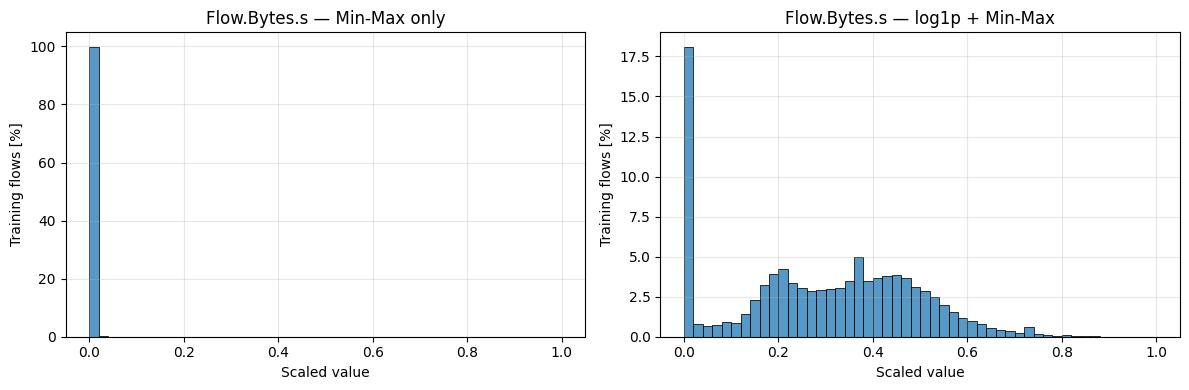

Flow.Bytes.s in the first bin [0, 0.02) — Min-Max only: 99.9%, log1p + Min-Max: 18.1% (exactly 0: 16.8%)


In [10]:
cont_cols = get_continuous_columns(X_train)
print(f"Continuous features: {len(cont_cols)}  |  binary (one-hot / flags): {X_train.shape[1] - len(cont_cols)}")

# Comparison: share of values below 0.01 for each continuous feature
plain = MinMaxScaler().fit_transform(X_train[cont_cols])
logged = MinMaxScaler().fit_transform(np.log1p(X_train[cont_cols]))
print(f"Features with >90% of values < 0.01 — Min-Max only: {((plain < 0.01).mean(axis=0) > 0.9).sum()}, "
      f"log1p + Min-Max: {((logged < 0.01).mean(axis=0) > 0.9).sum()}")

# Example: distribution of Flow.Bytes.s after the two normalizations
bytes_idx = cont_cols.index("Flow.Bytes.s")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, values, name in zip(axes, [plain[:, bytes_idx], logged[:, bytes_idx]], ["Min-Max only", "log1p + Min-Max"]):
    sns.histplot(values, bins=50, binrange=(0, 1), stat="percent", ax=ax)
    ax.set_title(f"Flow.Bytes.s — {name}")
    ax.set_xlabel("Scaled value")
    ax.set_ylabel("Training flows [%]")
    ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_scaling_histogram.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Flow.Bytes.s in the first bin [0, 0.02) — Min-Max only: {(plain[:, bytes_idx] < 0.02).mean() * 100:.1f}%, "
      f"log1p + Min-Max: {(logged[:, bytes_idx] < 0.02).mean() * 100:.1f}% "
      f"(exactly 0: {(X_train['Flow.Bytes.s'] == 0).mean() * 100:.1f}%)")

The histograms show the effect on `Flow.Bytes.s`. With Min-Max only, 99.9% of the training flows fall in the first bin:
for a model that sees $[0, 1]$ the feature is practically constant. After log1p the values spread over the whole
interval; the peak at 0 is the 17% of flows with no payload at all (exactly 0 bytes/s), which no monotonic transform can
spread. No KDE is drawn: with a hard bound and a point mass at 0, a KDE would smear that peak over negative values
(boundary bias).

In [11]:
X_train_scaled, X_test_scaled, scaler = scale_features(X_train, X_test)

print(f"Train range: [{X_train_scaled.to_numpy().min():.2f}, {X_train_scaled.to_numpy().max():.2f}]")
print(f"Test range:  [{X_test_scaled.to_numpy().min():.2f}, {X_test_scaled.to_numpy().max():.2f}]")
# Factor that multiplies 1 + x when a continuous feature is shifted by 0.05 in the scaled space
factor = pd.Series(np.exp(0.05 * scaler.data_range_), index=X_train_scaled.columns)[cont_cols].sort_values()
print("Shift of 0.05 -> 1 + x multiplied by:", factor.iloc[[0, 1, 2, len(factor) // 2, -1]].round(2).to_dict())
X_train_scaled.describe().T[["mean", "50%", "min", "max"]].head(10)

Train range: [0.00, 1.00]
Test range:  [0.00, 1.00]
Shift of 0.05 -> 1 + x multiplied by: {'min_seg_size_forward': 1.04, 'Down.Up.Ratio': 1.31, 'Min.Packet.Length': 1.44, 'Packet.Length.Variance': 2.35, 'Flow.Bytes.s': 3.01}


,mean,50%,min,max
Flow.Duration,0.693220,0.762224,0.0,1.0
Total.Fwd.Packets,0.145304,0.119674,0.0,1.0
Total.Backward.Packets,0.194767,0.163438,0.0,1.0
Total.Length.of.Fwd.Packets,0.293219,0.354890,0.0,1.0
Total.Length.of.Bwd.Packets,0.306773,0.340615,0.0,1.0
Fwd.Packet.Length.Max,0.446676,0.563307,0.0,1.0
Fwd.Packet.Length.Min,0.044708,0.000000,0.0,1.0
Fwd.Packet.Length.Mean,0.395588,0.474617,0.0,1.0
Fwd.Packet.Length.Std,0.413518,0.552525,0.0,1.0
Bwd.Packet.Length.Max,0.468562,0.546338,0.0,1.0


## 1.3 Exploratory data analysis

The analysis is done on the **training set only** (`X_train`, `y_train`): the test set stays unseen until the final
evaluation, so the choices inspired by the EDA (features to watch, transformations, attack targets) do not use
information from it. With ~400k flows the statistics are practically the same as on the whole dataset.

Conventions used in this section:
- The features are taken **before** log1p and Min-Max (`X_train`, not `X_train_scaled`), so the values are in their
  original units: bytes, packets, and microseconds for durations and inter-arrival times (the unit of CICFlowMeter).
- Most features are heavy-tailed and contain many zeros, so the plots use a **symmetric log axis** (`symlog`):
  linear between 0 and 1, logarithmic above. This way zeros remain visible next to values up to $10^8$.
- With 10 apps, a plot with 10 colors is hard to read. Distributions are compared side by side (one box per app),
  and scatter plots are drawn as small multiples: in each panel one app is colored and the other 9 are gray,
  which is exactly the one-vs-rest view of the detectors.
- The main figures are also saved in `results/plots/` for the report.

In [12]:
cont_cols = get_continuous_columns(X_train)
binary_cols = [c for c in X_train.columns if c not in cont_cols]
print(f"Training flows: {len(X_train):,}  |  continuous features: {len(cont_cols)}  |  binary features: {len(binary_cols)}")

Training flows: 403,758  |  continuous features: 54  |  binary features: 13


### Shape of the distributions

The continuous features belong to a few families:
- **volume**: packets and bytes in each direction (`Total.*`, `*.Header.Length`, `act_data_pkt_fwd`);
- **packet size**: min / max / mean / std of the packet lengths (`*Packet.Length*`, `*Segment.Size`, `Average.Packet.Size`);
- **timing**: duration, inter-arrival times (`*.IAT.*`), active and idle periods (`Active.*`, `Idle.*`) and rates (`*.s`);
- **TCP header**: initial windows (`Init_Win_bytes_*`), minimum header size (`min_seg_size_forward`), `Down.Up.Ratio`.

`summary_statistics` reports for each feature the share of zeros, mean, median, 99th percentile, maximum, skewness and the
share of points outside the Tukey fences $[Q_1 - 1.5\,\mathrm{IQR},\ Q_3 + 1.5\,\mathrm{IQR}]$, on the raw values and
after `log1p`. For a Gaussian variable only ~0.7% of the points are outside the fences.

In [13]:
stats = summary_statistics(X_train[cont_cols])

print(f"Features with skewness > 2: {(stats['skewness'] > 2).sum()} / {len(stats)}")
print(f"Features with > 5% Tukey outliers — raw: {(stats['tukey_outliers_%'] > 5).sum()}, "
      f"after log1p: {(stats['tukey_outliers_log_%'] > 5).sum()}")
print(f"Features with > 50% zeros: {(stats['zeros_%'] > 50).sum()}")
nonzero_median = stats[stats["median"] > 0]
print(f"Features with mean > 2 x median: {(nonzero_median['mean'] > 2 * nonzero_median['median']).sum()} / {len(nonzero_median)} (with non-zero median)")
stats.sort_values("skewness", ascending=False).round(2)

Features with skewness > 2: 44 / 54
Features with > 5% Tukey outliers — raw: 46, after log1p: 16
Features with > 50% zeros: 14
Features with mean > 2 x median: 32 / 40 (with non-zero median)


,zeros_%,mean,median,p99,max,skewness,tukey_outliers_%,tukey_outliers_log_%
act_data_pkt_fwd,25.08,41.44,3.00,7.000000e+02,2.145870e+05,162.90,11.10,2.30
Flow.Bytes.s,16.80,594076.78,819.13,1.200000e+07,3.833000e+09,126.00,17.24,0.03
Total.Fwd.Packets,0.00,85.00,7.00,1.491430e+03,2.147210e+05,123.03,14.22,5.38
Total.Length.of.Fwd.Packets,17.62,11203.29,672.00,4.800988e+04,9.305026e+07,97.92,10.71,0.03
Fwd.Header.Length,0.00,2374.88,200.00,4.209144e+04,4.297932e+06,78.14,14.31,4.31
Min.Packet.Length,87.87,1.11,0.00,6.000000e+00,1.460000e+03,67.05,12.13,12.13
Total.Backward.Packets,9.83,128.20,6.00,2.478000e+03,1.481680e+05,54.28,15.82,5.49
Total.Length.of.Bwd.Packets,25.68,249521.24,786.00,5.745207e+06,3.178298e+08,48.93,17.53,0.00
Bwd.Header.Length,9.83,3483.84,192.00,6.825832e+04,4.601096e+06,47.30,15.02,2.54
Fwd.Packet.Length.Min,82.99,3.76,0.00,5.500000e+01,4.380000e+03,27.94,17.01,17.01


Observations:
- **Heavy tails everywhere.** Almost all features are strongly right-skewed (skewness up to ~160). For example,
  `Flow.Bytes.s` has a median of ~800 bytes/s, a 99th percentile of $1.2 \cdot 10^7$ and a maximum of $3.8 \cdot 10^9$:
  most flows are small, while a few "elephant" flows (long downloads and sessions) span several orders of magnitude.
- **The mean is not representative.** Because of the tails, the mean is pulled far above the median: it is more than
  twice the median in 32 of the 40 features with non-zero median (`Flow.Bytes.s`: mean ~594k bytes/s vs median ~800,
  `Total.Fwd.Packets`: 85 vs 7). The median and the percentiles describe a "typical" flow much better.
- **The outliers are not errors.** On the raw values the Tukey rule flags 10-20% of the flows for most features
  (46 features above 5%), far from the 0.7% expected for a Gaussian. After `log1p` the share drops to 0 for most of
  them, and the 16 features still above 5% are almost all the zero-inflated ones described below. These points are
  the natural tail of the distribution, i.e. real large flows, so they are kept and handled by the log transform
  (Section 1.2) instead of being removed.
- **Zero-inflated features.** `Active.*` and `Idle.*` are 0 in ~77% of the flows (CICFlowMeter fills them only when
  the flow has idle periods), and the minimum packet lengths are 0 in 83-88% (at least one packet without payload,
  e.g. a pure ACK). For these features IQR = 0, so every non-zero value is an "outlier" even after log1p:
  the share of non-zero values is the interesting quantity, not the box.
- **Physical bounds are visible.** `Flow.Duration` never exceeds $1.2 \cdot 10^8$ µs = 120 s (the flow timeout of
  CICFlowMeter, longer connections are split), `Init_Win_bytes_*` never exceed 65535 (16-bit TCP window field) and
  `min_seg_size_forward` only takes the values 20, 32, 40, 44 (TCP header size without and with options).

### Binary features per app

The 13 binary features (one-hot destination port and protocol, TCP flags, missing-window flag) are summarized by the
share of flows of each app where they are equal to 1.

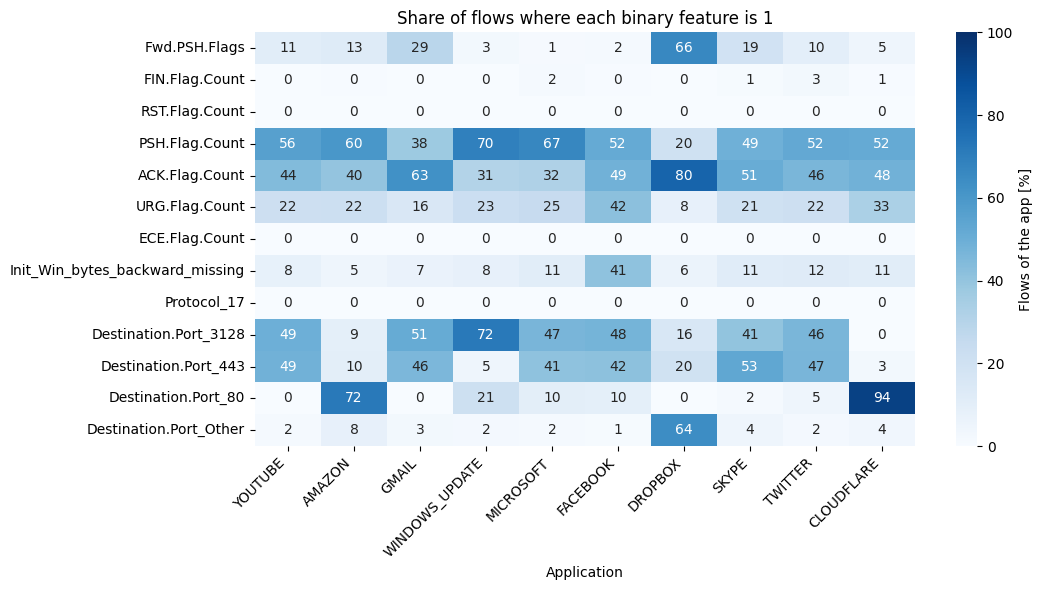

In [14]:
binary_share = X_train[binary_cols].groupby(y_train).mean().loc[APPS] * 100

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(binary_share.T, cmap="Blues", annot=True, fmt=".0f", vmin=0, vmax=100,
            cbar_kws={"label": "Flows of the app [%]"}, ax=ax)
ax.set_xlabel("Application")
ax.set_title("Share of flows where each binary feature is 1")
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_binary_features.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
# DROPBOX: inverted flows (client's ephemeral port in Destination.Port) vs the others
dropbox = X_train[y_train == "DROPBOX"]
is_inverted = dropbox["Destination.Port_Other"].map({0: "not inverted", 1: "inverted"})
dropbox_cols = ["Fwd.PSH.Flags", "Idle.Max", "Flow.Duration", "Init_Win_bytes_forward"]
pd.concat([
    dropbox.groupby(is_inverted).size().rename("flows"),
    dropbox.groupby(is_inverted)[dropbox_cols].median().add_prefix("median "),
    dropbox.groupby(is_inverted)["Fwd.PSH.Flags"].mean().mul(100).rename("Fwd.PSH.Flags = 1 [%]"),
], axis=1).round(1)

,flows,median Fwd.PSH.Flags,median Idle.Max,median Flow.Duration,median Init_Win_bytes_forward,Fwd.PSH.Flags = 1 [%]
Destination.Port_Other,,,,,,
inverted,12919,1.0,57252521.0,76843578.0,126.0,94.6
not inverted,7179,0.0,0.0,46843323.0,8192.0,15.1


Observations:
- **The destination port alone almost identifies some apps.** 94% of the CLOUDFLARE flows and 72% of the AMAZON flows
  go to port 80 (plain HTTP, typical of CDN content), against at most ~21% for the other apps. WINDOWS_UPDATE goes
  through the proxy port 3128 in 72% of the flows and almost never to port 443 (5%).
- **DROPBOX is dominated by `Destination.Port_Other` (64%)**: these are the inverted flows discussed in Section 1.2
  (`Source.Port` = 443, client's ephemeral port in `Destination.Port`). The table above shows that they are also
  different in behavior: `Fwd.PSH.Flags` (PSH or SYN, see Section 1.2) is set in almost all of them, they last longer and have long idle periods.
  They look like long-lived connections kept open by the client whose beginning was not observed, so the first packet
  seen came from the server. In these flows *forward* means server → client, which explains several DROPBOX-specific
  patterns below (e.g. its small `Init_Win_bytes_forward`, which is actually the window of the server).
- **CLOUDFLARE never goes through the proxy** (≈ 0% of its flows to port 3128) and AMAZON rarely does (9%), against
  16-72% for the other apps. Through the proxy the destination address is the proxy itself, so a label based on the
  server address cannot be assigned: this suggests that nDPI recognizes these two providers mostly from their IP
  addresses. Part of the information carried by the port would then come from how the labels were produced, not from
  the behavior of the apps, a risk of shortcut learning to keep in mind.
- **FACEBOOK** has `Init_Win_bytes_backward_missing` set in 41% of the flows (5-12% for the other apps): these are
  flows where the server sent no packet at all.
- **Almost constant features**: UDP (`Protocol_17`) is ≤ 0.2% for every app, the `RST` and `ECE` flags are ≈ 0 and
  `FIN` ≤ 2.5%. They carry almost no information, as confirmed by the mutual information below.

### Which features separate the apps?

Two complementary measures rank the features without training any model:

- **Univariate ROC-AUC** (`univariate_auc`): for each app, the feature alone is used as the score of the one-vs-rest
  detector. AUC = P(value of a random flow of the app > value of a random flow of the other apps): 0.5 means no
  separation, values towards 1 (0) mean that the app has larger (smaller) values. It is computed for all features and
  apps at once from the ranks (Mann-Whitney U statistic [5]), so it does not depend on scaling or on monotonic transforms
  such as log1p. It only detects *monotonic* differences, i.e. distributions shifted up or down.
- **Mutual information** (`mutual_information`) between the feature and the 10-class label, estimated with the k-NN
  estimator of scikit-learn [6, 7] on a stratified sample of 100k flows. It is 0 if the feature is independent of the app
  and captures any kind of dependence, also non-monotonic ones (e.g. an app using a specific value in the middle of
  the range).
  The k-NN estimator assumes continuous values and is less reliable for features with many ties (the zero-inflated
  ones, or those with few distinct values), while the 0/1 features are estimated with the discrete formula: the values
  are used to rank the features, not as exact amounts of information.

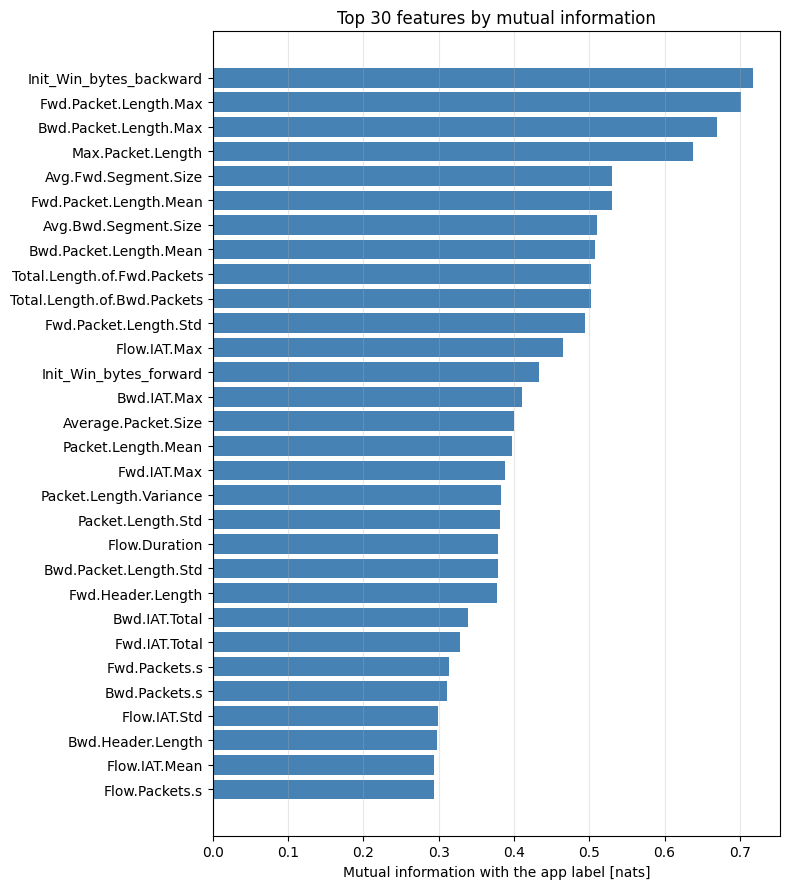

Lowest mutual information: {'Min.Packet.Length': 0.018, 'URG.Flag.Count': 0.013, 'FIN.Flag.Count': 0.003, 'Protocol_17': 0.0, 'RST.Flag.Count': 0.0, 'ECE.Flag.Count': 0.0}


In [16]:
auc = univariate_auc(X_train, y_train, APPS)
mi = mutual_information(X_train, y_train, n_samples=100_000, seed=42)

top_mi = mi.head(30)[::-1]
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(top_mi.index, top_mi.to_numpy(), color="steelblue")
ax.set_xlabel("Mutual information with the app label [nats]")
ax.set_title("Top 30 features by mutual information")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_mutual_information.png", dpi=150, bbox_inches="tight")
plt.show()

print("Lowest mutual information:", mi.tail(6).round(3).to_dict())

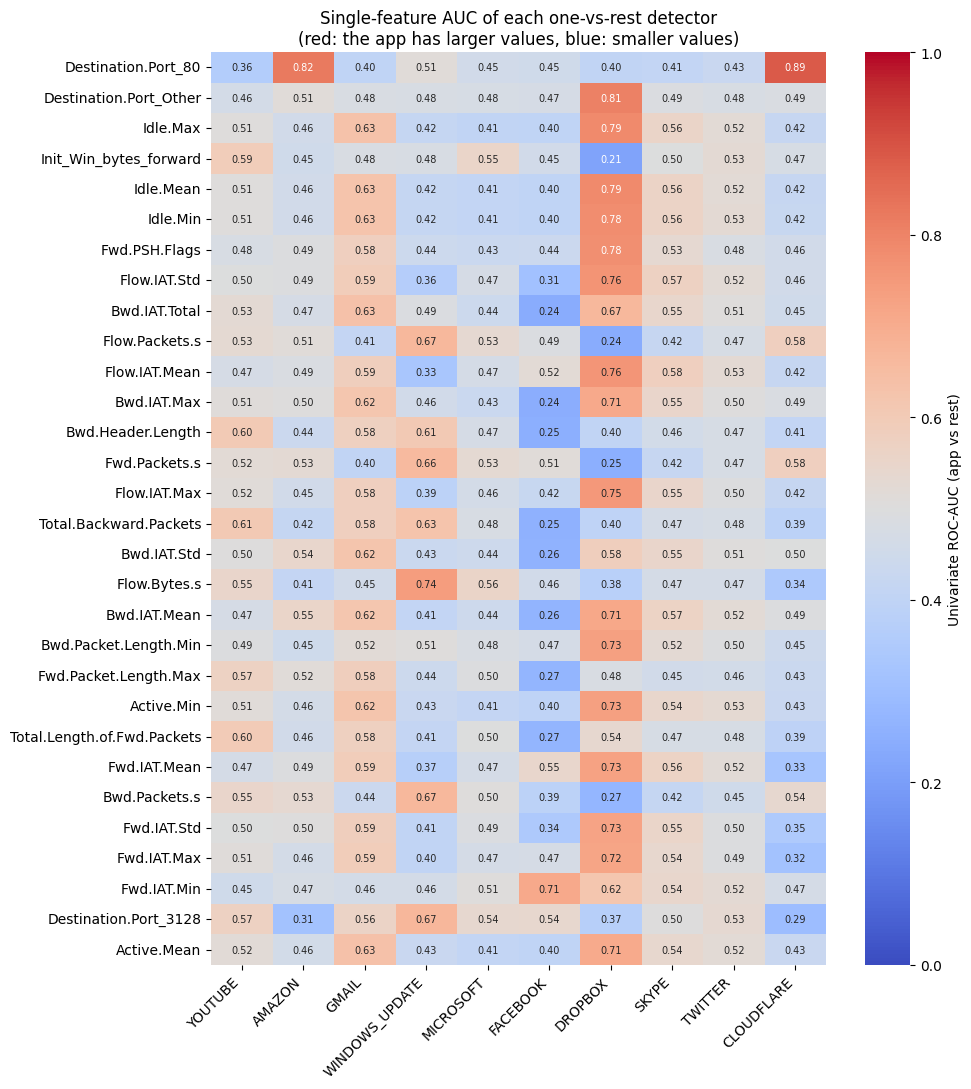

,best_feature,auc,"max(auc, 1 - auc)"
YOUTUBE,Destination.Port_80,0.36,0.64
AMAZON,Destination.Port_80,0.82,0.82
GMAIL,Active.Max,0.64,0.64
WINDOWS_UPDATE,Flow.Bytes.s,0.74,0.74
MICROSOFT,Idle.Max,0.41,0.59
FACEBOOK,Bwd.IAT.Total,0.24,0.76
DROPBOX,Destination.Port_Other,0.81,0.81
SKYPE,Destination.Port_443,0.60,0.60
TWITTER,Destination.Port_80,0.43,0.57
CLOUDFLARE,Destination.Port_80,0.89,0.89


In [17]:
# Features sorted by their best separation over the 10 apps
separation = (auc - 0.5).abs()
top_auc = separation.max(axis=1).sort_values(ascending=False).head(30).index

fig, ax = plt.subplots(figsize=(10, 11))
sns.heatmap(auc.loc[top_auc], cmap="coolwarm", center=0.5, vmin=0, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, cbar_kws={"label": "Univariate ROC-AUC (app vs rest)"}, ax=ax)
ax.set_title("Single-feature AUC of each one-vs-rest detector\n(red: the app has larger values, blue: smaller values)")
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_univariate_auc.png", dpi=150, bbox_inches="tight")
plt.show()

# Best single feature of each detector. AUC < 0.5 also separates (the app has smaller values),
# so the strength of the separation is max(AUC, 1 - AUC)
best_feature = separation.idxmax()
best_auc = pd.Series([auc.loc[feature, app] for app, feature in best_feature.items()], index=best_feature.index)
pd.DataFrame({
    "best_feature": best_feature,
    "auc": best_auc,
    "max(auc, 1 - auc)": np.maximum(best_auc, 1 - best_auc),
}).round(2)

Observations:
- **No single feature is enough for most apps.** The best single feature reaches an AUC of 0.89 for CLOUDFLARE
  (`Destination.Port_80`), ≈ 0.8 for AMAZON and DROPBOX and ≈ 0.75 for FACEBOOK and WINDOWS_UPDATE, but only 0.57-0.64 (as $\max(\mathrm{AUC}, 1 - \mathrm{AUC})$)
  for TWITTER, MICROSOFT, SKYPE, GMAIL and YOUTUBE: their detectors will need combinations of features and
  non-linear models.
- **Patterns per app** (red = larger values than the rest, blue = smaller):
  - DROPBOX: long idle periods and inter-arrival times (`Idle.*`, `Flow.IAT.*` ≈ 0.75-0.79), `Fwd.PSH.Flags` and low
    packet rates (≈ 0.25): slow, long-lived connections.
  - WINDOWS_UPDATE: high throughput (`Flow.Bytes.s` 0.74) and many, large backward packets: bulk downloads from the server.
  - FACEBOOK: few backward packets and short backward activity (`Bwd.*` ≈ 0.24-0.27), consistent with the 41% of
    flows without any answer from the server.
  - AMAZON and CLOUDFLARE: port 80; CLOUDFLARE flows are also short (`Fwd.IAT.*` ≈ 0.32).
- **Mutual information tells a different story.** Its top features are `Init_Win_bytes_backward` and the maximum
  packet lengths, whose AUC is close to 0.5 for most apps. Their relation with the app is not monotonic: specific
  *values* identify specific apps, as shown below for the initial window.

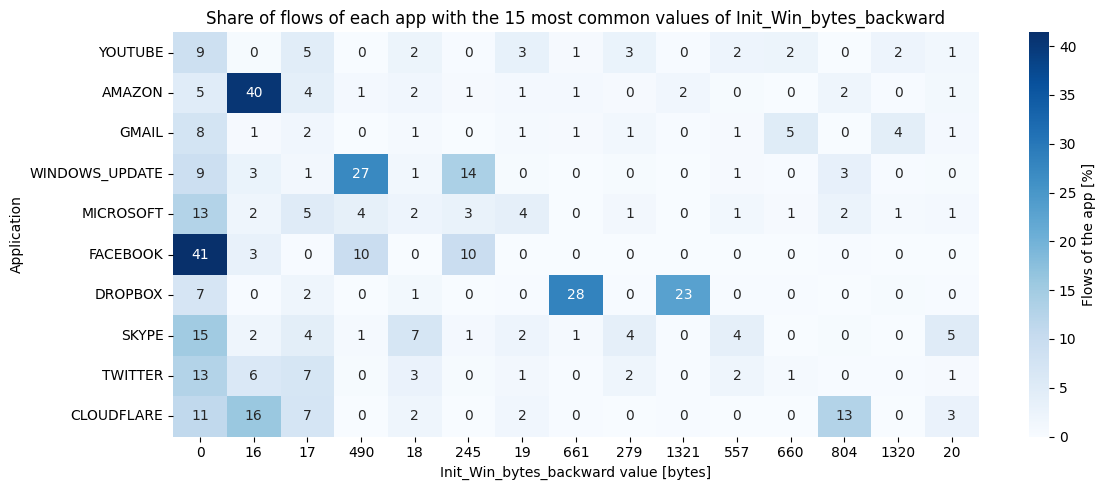

Init_Win_bytes_backward between 1 and 1023 bytes: 79.1% of the flows


In [18]:
col = "Init_Win_bytes_backward"
top_values = X_train[col].value_counts().head(15).index
value_share = pd.crosstab(y_train, X_train[col], normalize="index").loc[APPS, top_values] * 100

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(value_share, cmap="Blues", annot=True, fmt=".0f", vmin=0, cbar_kws={"label": "Flows of the app [%]"}, ax=ax)
ax.set_xlabel(f"{col} value [bytes]")
ax.set_ylabel("Application")
ax.set_title(f"Share of flows of each app with the 15 most common values of {col}")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_init_win_backward.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"{col} between 1 and 1023 bytes: {X_train[col].between(1, 1023).mean() * 100:.1f}% of the flows")

`Init_Win_bytes_backward` is the TCP window field of the first packet sent by the **responder** (the server, or the
Squid proxy for the flows to port 3128). Its values are strongly app-specific: 40% of the AMAZON flows have value 16,
41% of the WINDOWS_UPDATE flows 490 or 245, 51% of the DROPBOX flows 661 or 1321. The value 0 includes the flows
where the window was not observed (the `-1` sentinel replaced in Section 1.2), and is the most common one for
FACEBOOK. 79% of the values are below 1024 bytes, far from a real initial window (the client values in `Init_Win_bytes_forward` are
typically 5840, 8192, 14600 or 65535). Only the SYN and SYN-ACK carry the window unscaled; the later segments carry it
divided by the window-scale factor negotiated in the handshake [8]. So in most flows the value of the server does not
come from its SYN-ACK: it combines the window with the scale factor and depends on the state of the connection. It is
very informative, but not a pure fingerprint of the server.

`Init_Win_bytes_forward` is the same field set by the **client**. Unlike the server window, it is directly under the
control of an attacker generating the traffic, so a rare value of it is a natural backdoor trigger (Section 4).

**Specific values vs ranges of values.** The univariate AUC, like any monotonic measure (Pearson or Spearman correlation
between the feature and the 0/1 label would behave the same way), treats a feature as an ordered quantity and only
asks whether an app has *larger or smaller* values. For `Init_Win_bytes_backward` this is the wrong question: 490 and
486 are close numbers, yet they may come from different server stacks. To check where the information is,
`exact_vs_range_mi` computes the mutual information with the app label in two ways, on the full training set:
- **exact values**: every distinct value is a category, as if the feature were one-hot encoded;
- **ranges**: the feature is cut into 20 quantile bins, so only the order of the values is kept (equal values always
  fall in the same bin, so with many ties some bins merge).

Both are corrected for the bias of the estimator (Miller-Madow [9]), which grows with the number of distinct values.
The uncorrected mutual information can only grow when the partition is refined (the ranges are a function of the exact
values), so a ratio above 1 alone proves nothing. As a control, the table also includes three packet counts
(`Total.Fwd.Packets`, `Total.Backward.Packets`, `act_data_pkt_fwd`): they also have thousands of distinct values, but
they are plain quantities, with no reason for a specific count to identify an app. The comparison is
meaningful only for features with a limited number of distinct values: the timing features have hundreds of thousands
of almost unique values, so each "exact value" contains one or two flows and the estimate is meaningless. The table
keeps the top-15 features by mutual information with fewer than 10,000 distinct values, plus the three controls.

In [19]:
top_mi_features = mi.head(15).index
few_values = [f for f in top_mi_features if X_train[f].nunique() < 10_000]
# Control: packet counts, with thousands of distinct values too, but plain quantities
controls = ["Total.Fwd.Packets", "Total.Backward.Packets", "act_data_pkt_fwd"]
mi_values = exact_vs_range_mi(X_train[few_values + controls], y_train, n_bins=20)
mi_values["exact / ranges"] = mi_values["mi_exact_values"] / mi_values["mi_quantile_bins"]
mi_values["best max(auc, 1 - auc)"] = np.maximum(auc.loc[few_values + controls], 1 - auc.loc[few_values + controls]).max(axis=1)
mi_values.round(3)

,distinct_values,mi_exact_values,mi_quantile_bins,exact / ranges,"best max(auc, 1 - auc)"
Init_Win_bytes_backward,5227.0,0.702,0.284,2.473,0.698
Fwd.Packet.Length.Max,3934.0,0.699,0.337,2.077,0.732
Bwd.Packet.Length.Max,7692.0,0.659,0.256,2.575,0.666
Max.Packet.Length,7909.0,0.631,0.232,2.722,0.656
Init_Win_bytes_forward,8457.0,0.392,0.161,2.430,0.786
Total.Fwd.Packets,3861.0,0.161,0.148,1.085,0.666
Total.Backward.Packets,5274.0,0.128,0.143,0.897,0.746
act_data_pkt_fwd,2906.0,0.093,0.100,0.931,0.698


Observations:
- **The hypothesis is confirmed for the initial windows and the maximum packet lengths.** Using their exact values gives
  2 to 2.7 times the information obtained from their ranges, while for the packet counts used as control the two
  estimates are almost equal (ratio 0.9-1.1): the gap is not an artifact of the finer partition. Their best univariate
  AUC stays around 0.65-0.8. These
  features are numeric in form but **partly categorical in nature**: specific values are signatures of the TCP endpoints
  (windows) or of fixed-size protocol messages (maximum sizes, the horizontal and vertical lines in the scatter plots
  below). The order of the values still carries some information (the MI on ranges is not 0), so they are not purely
  categorical either.
- **For the other top features it does not apply.** The packet length means, totals and timing features have a large
  mutual information because the apps occupy different *ranges* of values, often in the middle of the distribution
  (e.g. an app with medium durations is neither "larger" nor "smaller" than the rest). This multi-class,
  non-monotonic pattern is also missed by the one-vs-rest AUC, but it has nothing to do with specific values.
- **Implications for the models.** One-hot encoding these features is not practical (thousands of values, many seen
  only a few times). Decision trees do not need it, since two splits can isolate a single value. For the MLP, after
  log1p and Min-Max two "fingerprint" values like 486 and 490 become almost identical inputs, so it can only learn them
  with very narrow decision regions. If the MLP performs poorly, a possible improvement for Section 2 is to add
  one-hot indicators for the few most frequent values of these features (as done for the ports) and group the rest
  into "Other".

### Correlation analysis

Pearson's $r$ measures linear dependence; Spearman's $r_s$ is Pearson computed on the ranks and measures monotonic
dependence. Both are computed on the 54 continuous features. The rows and columns of the heatmaps are sorted by
hierarchical clustering on the distance $1 - |r_s|$ (`feature_clusters`), so that groups of correlated features
appear as blocks along the diagonal.

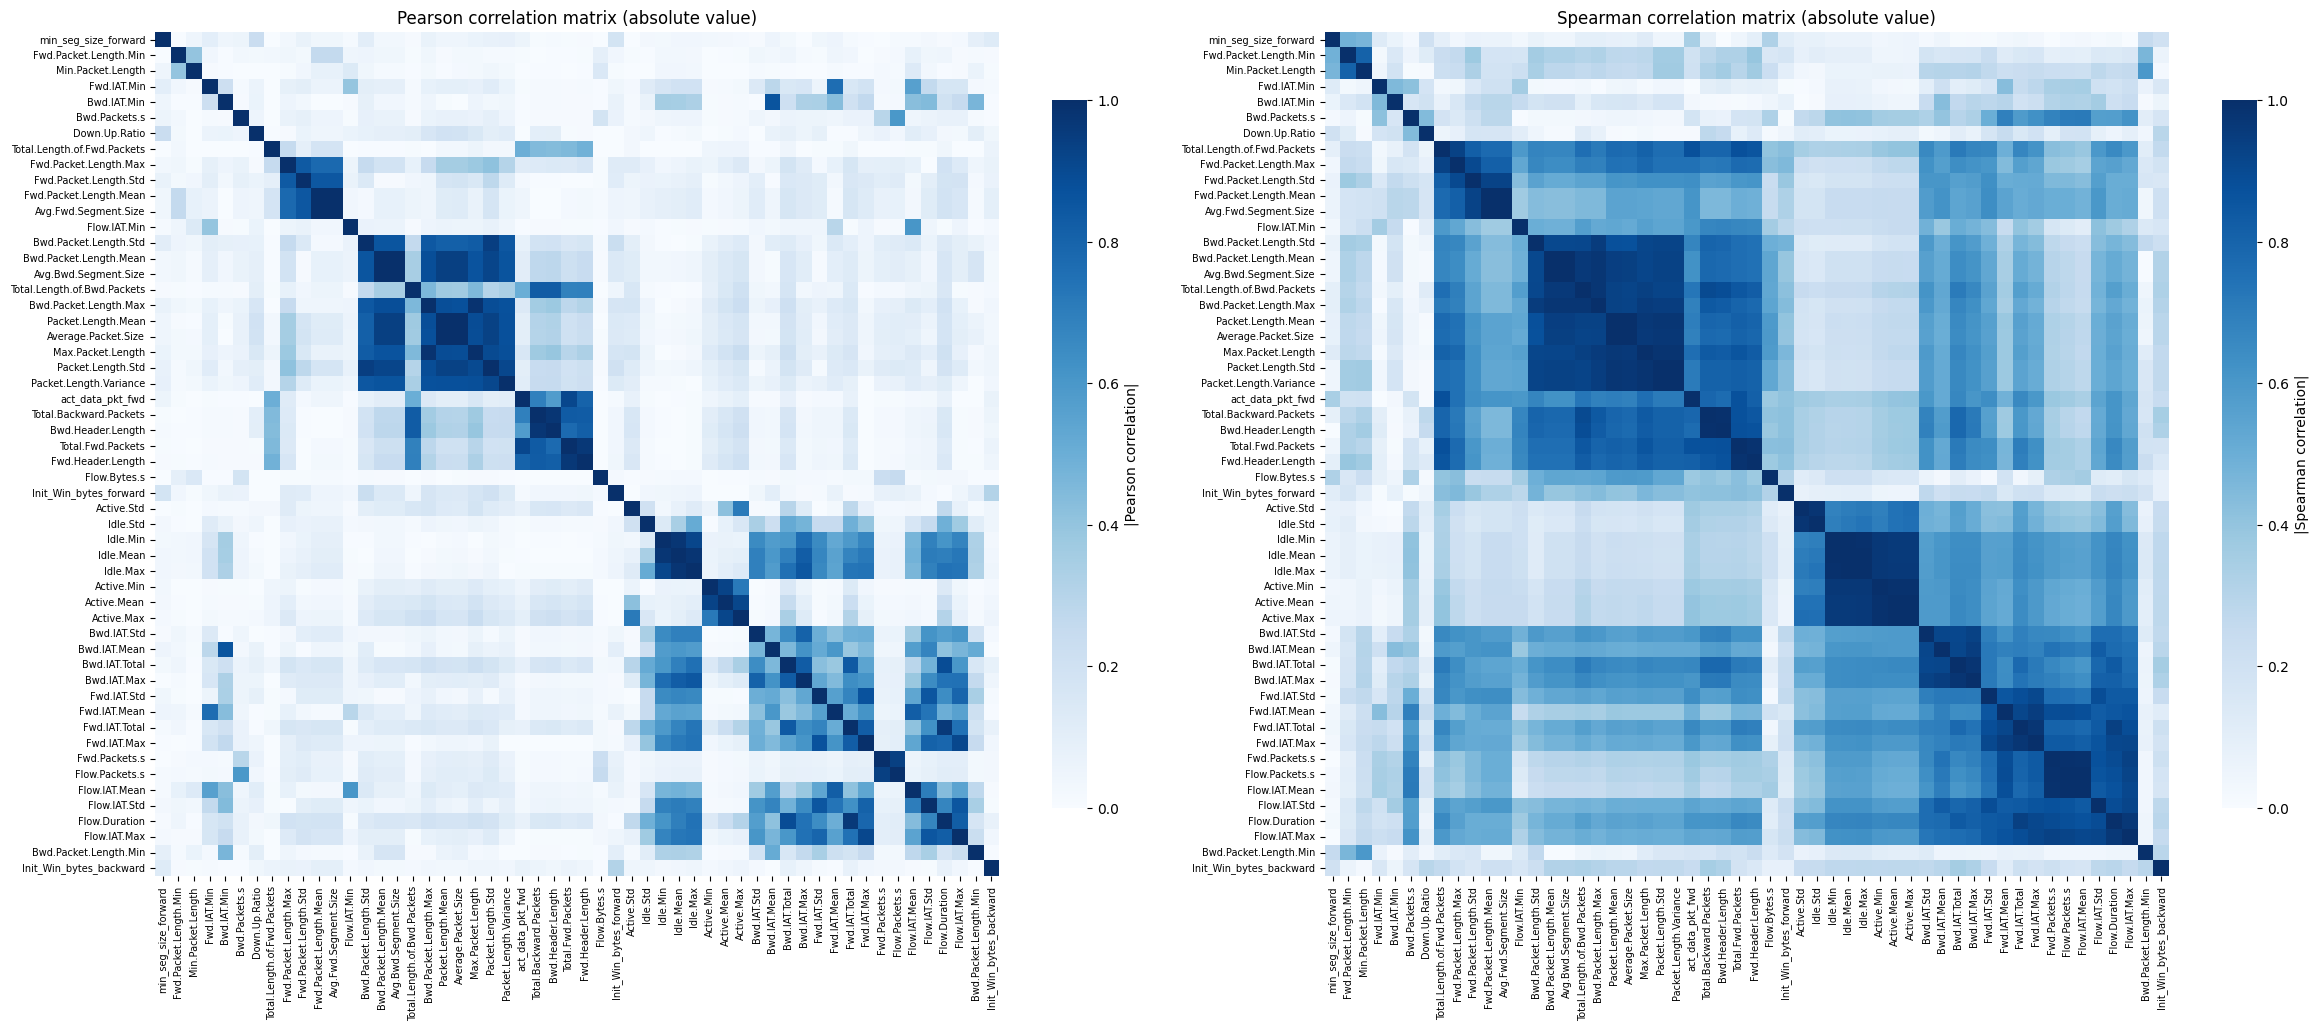

In [20]:
corr_p = X_train[cont_cols].corr()
corr_s = X_train[cont_cols].corr(method="spearman")
clusters = feature_clusters(corr_s, threshold=0.9)
order = clusters.index

fig, axes = plt.subplots(1, 2, figsize=(24, 11))
for ax, corr, name in zip(axes, [corr_p, corr_s], ["Pearson", "Spearman"]):
    sns.heatmap(corr.loc[order, order].abs(), cmap="Blues", vmin=0, vmax=1, square=True, xticklabels=True,
                yticklabels=True, cbar_kws={"label": f"|{name} correlation|", "shrink": 0.7}, ax=ax)
    ax.set_title(f"{name} correlation matrix (absolute value)")
    ax.tick_params(labelsize=7)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
pairs = correlation_pairs(pearson=corr_p, spearman=corr_s, pearson_log1p=np.log1p(X_train[cont_cols]).corr())
methods = ["pearson", "spearman", "pearson_log1p"]
pd.DataFrame({
    "pairs with |corr| >= 0.9": (pairs[methods].abs() >= 0.9).sum(),
    "mean |corr|": pairs[methods].abs().mean(),
}).round(3)

,pairs with |corr| >= 0.9,mean |corr|
pearson,26,0.161
spearman,87,0.424
pearson_log1p,89,0.449


In [22]:
# Pairs where the monotonic dependence is much stronger than the linear one
pairs["spearman - pearson"] = pairs["spearman"].abs() - pairs["pearson"].abs()
both_nonzero = (X_train["Active.Min"] > 0) & (X_train["Idle.Max"] > 0)
print(f"Spearman Active.Min vs Idle.Max: all flows {corr_s.loc['Active.Min', 'Idle.Max']:.2f}, "
      f"flows where both are non-zero {X_train.loc[both_nonzero, ['Active.Min', 'Idle.Max']].corr('spearman').iloc[0, 1]:.2f}")
pairs.sort_values("spearman - pearson", ascending=False).head(8).round(3)

Spearman Active.Min vs Idle.Max: all flows 0.97, flows where both are non-zero -0.18


,feature_1,feature_2,pearson,spearman,pearson_log1p,spearman - pearson
651,Flow.Packets.s,Flow.IAT.Mean,-0.064,-0.999,-0.985,0.935
705,Flow.IAT.Mean,Fwd.Packets.s,-0.058,-0.991,-0.969,0.933
1423,Active.Min,Idle.Max,0.060,0.965,0.899,0.905
1421,Active.Min,Idle.Mean,0.065,0.965,0.899,0.901
1424,Active.Min,Idle.Min,0.067,0.967,0.899,0.899
1420,Active.Max,Idle.Min,0.065,0.958,0.937,0.893
1409,Active.Mean,Idle.Min,0.073,0.959,0.939,0.886
1406,Active.Mean,Idle.Mean,0.086,0.960,0.941,0.874


In [23]:
feature_groups = [list(g) for g in clusters.groupby(clusters).groups.values() if len(g) > 1]
print(f"{len(cont_cols)} continuous features -> {clusters.nunique()} groups where every pair has |r_s| >= 0.9")
print(f"Groups with more than one feature ({len(feature_groups)}):")
for group in feature_groups:
    print(" -", ", ".join(group))

54 continuous features -> 27 groups where every pair has |r_s| >= 0.9
Groups with more than one feature (11):
 - Total.Length.of.Fwd.Packets, Fwd.Packet.Length.Max
 - Fwd.Packet.Length.Std, Fwd.Packet.Length.Mean, Avg.Fwd.Segment.Size
 - Bwd.Packet.Length.Mean, Avg.Bwd.Segment.Size, Total.Length.of.Bwd.Packets, Bwd.Packet.Length.Max, Packet.Length.Mean, Average.Packet.Size, Max.Packet.Length, Packet.Length.Std, Packet.Length.Variance
 - Total.Backward.Packets, Bwd.Header.Length
 - Total.Fwd.Packets, Fwd.Header.Length
 - Active.Std, Idle.Std
 - Idle.Min, Idle.Mean, Idle.Max, Active.Min, Active.Mean, Active.Max
 - Bwd.IAT.Std, Bwd.IAT.Mean, Bwd.IAT.Total, Bwd.IAT.Max
 - Fwd.IAT.Mean, Fwd.IAT.Total, Fwd.IAT.Max
 - Fwd.Packets.s, Flow.Packets.s, Flow.IAT.Mean
 - Flow.Duration, Flow.IAT.Max


In [24]:
# Pairs with an almost perfect rank correlation: are they the same feature?
near_identical = pairs.loc[pairs["spearman"].abs() >= 0.999, ["feature_1", "feature_2", "pearson", "spearman"]].copy()
near_identical["max_relative_difference"] = [
    ((X_train[a] - X_train[b]).abs() / X_train[a].abs().clip(lower=1)).max()
    for a, b in zip(near_identical["feature_1"], near_identical["feature_2"])
]

# The variance is by definition the square of the std
rel_err = ((X_train["Packet.Length.Std"] ** 2 - X_train["Packet.Length.Variance"]).abs()
           / X_train["Packet.Length.Variance"].clip(lower=1))
print(f"max relative difference between Packet.Length.Std^2 and Packet.Length.Variance = {rel_err.max():.2e}")
near_identical.sort_values("spearman", key=abs, ascending=False)

max relative difference between Packet.Length.Std^2 and Packet.Length.Variance = 1.40e-06


,feature_1,feature_2,pearson,spearman,max_relative_difference
557,Bwd.Packet.Length.Mean,Avg.Bwd.Segment.Size,1.000000,1.000000,9.578654e-07
382,Fwd.Packet.Length.Mean,Avg.Fwd.Segment.Size,1.000000,1.000000,8.941049e-07
1278,Packet.Length.Std,Packet.Length.Variance,0.910520,1.000000,5.172765e+03
1404,Active.Mean,Active.Max,0.915872,0.999488,1.998957e+01
1263,Packet.Length.Mean,Average.Packet.Size,0.999288,0.999270,5.000004e-01


Observations:
- **On raw data Pearson underestimates the dependence.** The mean $|r|$ is 0.16 against 0.42 for Spearman, and only
  26 pairs have $|r| \ge 0.9$ against 87: the extreme values of the heavy tails dominate the sums in $r$. The clearest
  example is `Flow.Packets.s` vs `Flow.IAT.Mean`: $r = -0.06$ but $r_s = -0.999$, because the packet rate is the
  inverse of the mean inter-arrival time, a perfectly monotonic but non-linear relation. After `log1p` the Pearson
  correlation (mean 0.45, 89 pairs) is very close to Spearman: in the space seen by the models these monotonic
  relations become almost linear.
- Some Spearman correlations are inflated by **shared zeros**: `Active.*` and `Idle.*` are 0 together in ~77% of the
  flows, and these tied ranks alone give $r_s$ between 0.96 and 0.97: on the flows where both are non-zero, $r_s$ between
  `Active.Min` and `Idle.Max` is only −0.18 (printed above the pairs table).
- **Strong redundancy.** The 54 continuous features collapse into 27 groups in which every pair has $|r_s| \ge 0.9$:
  sizes and lengths, packet counts and header lengths, IAT statistics, active/idle periods. Redundancy is harmless for
  trees and tolerable for the MLP, but it matters for the attacks of Section 3: perturbing one feature without the
  correlated ones produces flows that are internally inconsistent.
- **Three features are copies of others** (last table). `Avg.Fwd.Segment.Size` and `Avg.Bwd.Segment.Size` have
  $r = r_s = 1$ with `Fwd.Packet.Length.Mean` and `Bwd.Packet.Length.Mean`, and the values coincide up to float
  rounding (relative difference $10^{-6}$), which is why the exact equality check of Section 1.2 missed them.
  `Packet.Length.Variance` has $r_s = 1$ but $r = 0.91$ with `Packet.Length.Std`: the relation is monotonic but not
  linear, and indeed the variance is the square of the std. The other pairs with $r_s \approx 1$ are different
  features: e.g. `Packet.Length.Mean` and `Average.Packet.Size` differ by up to 50% in some flows.

### Distributions of the most informative features

To plot the most interesting features without showing the same information several times, `select_non_redundant`
goes through the continuous features in order of mutual information (without the three exact copies found above,
see `REDUNDANT_FEATURES` below) and keeps a feature only if $|r_s| < 0.9$ with
all the features already kept. The first 8 are shown as boxplots per app (whiskers at 1.5 IQR; outliers are not
drawn, since they are thousands of points per app and were quantified above).

Selected features: ['Init_Win_bytes_backward', 'Fwd.Packet.Length.Max', 'Bwd.Packet.Length.Max', 'Fwd.Packet.Length.Mean', 'Flow.IAT.Max', 'Init_Win_bytes_forward', 'Bwd.IAT.Max', 'Fwd.Header.Length']


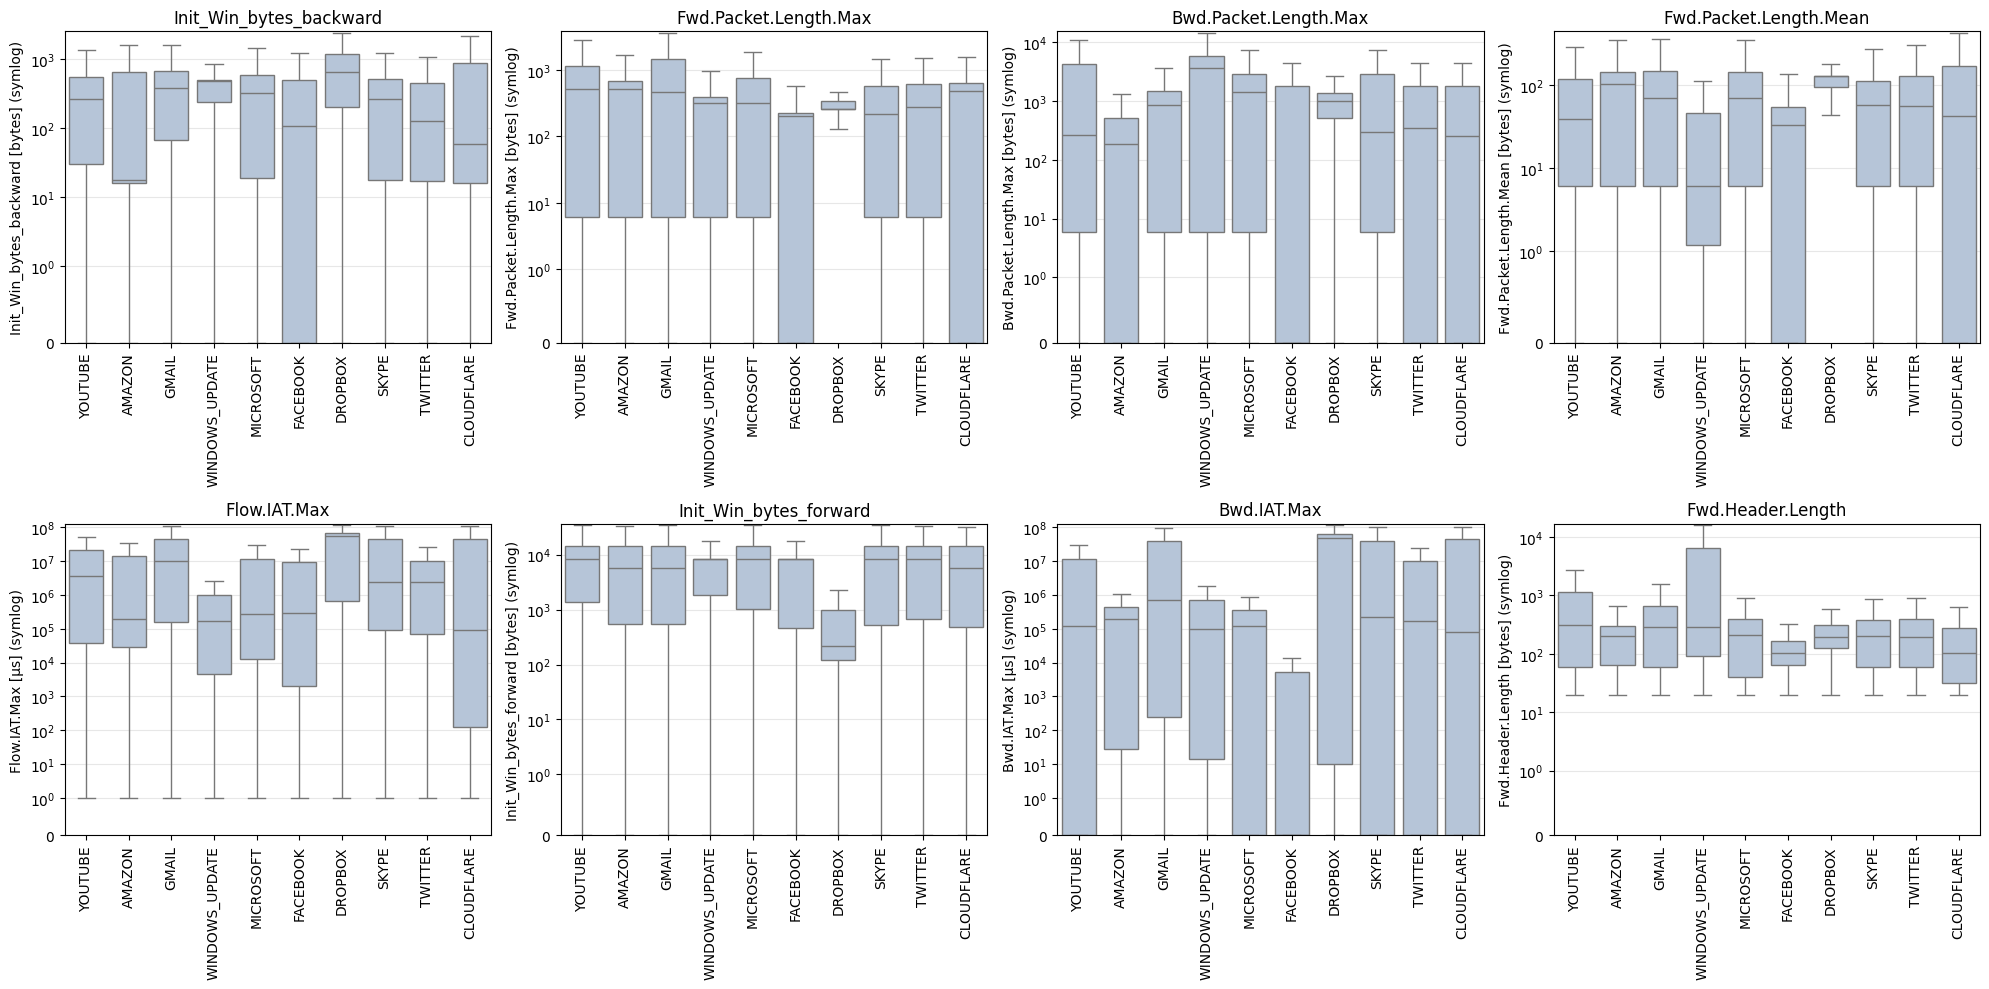

In [25]:
mi_cont = mi[mi.index.isin(cont_cols) & ~mi.index.isin(REDUNDANT_FEATURES)]
top_features = select_non_redundant(mi_cont.index, corr_s, threshold=0.9)[:8]
print("Selected features:", top_features)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(x=y_train, y=X_train[feature], order=APPS, color="lightsteelblue", showfliers=False, linewidth=1, ax=ax)
    ax.set_yscale("symlog", linthresh=1)
    ax.set_ylim(bottom=0)
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel(f"{feature_label(feature)} (symlog)")
    ax.tick_params(axis="x", rotation=90)
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

Observations (the y axes are logarithmic, so one grid line is a factor 10):
- `Init_Win_bytes_backward`: narrow boxes for the apps with a few dominant values (WINDOWS_UPDATE, DROPBOX),
  very wide ones for YOUTUBE, MICROSOFT and CLOUDFLARE.
- `Fwd.Packet.Length.Max` and `Bwd.Packet.Length.Max`: WINDOWS_UPDATE and MICROSOFT receive much larger packets than the
  others (median `Bwd.Packet.Length.Max` 3670 and 1436 bytes), while FACEBOOK sends and receives small packets
  (its median backward maximum is 0, i.e. no payload from the server). DROPBOX has a very narrow forward maximum,
  again an effect of the inverted, repetitive flows. Values above the 1500-byte Ethernet MTU are probably due to
  segmentation offloading at the capture point (several TCP segments seen as one packet).
- `Flow.IAT.Max` and `Bwd.IAT.Max`: DROPBOX has the longest silences (tens of seconds), GMAIL and YOUTUBE
  also have long gaps; FACEBOOK has `Bwd.IAT.Max` = 0 for most flows (fewer than two backward packets).
- `Init_Win_bytes_forward` is similar for most apps (typical client windows 5840, 8192, 14600, 65535), except DROPBOX,
  whose inverted flows report the window of the server.
- `Fwd.Packet.Length.Mean` is lowest for WINDOWS_UPDATE: the client mostly sends
  small acknowledgements while downloading, which also gives it the largest `Fwd.Header.Length` (many forward packets).
- In every box the whiskers span several orders of magnitude and the boxes of different apps overlap: the
  differences are in the location and in specific values, not a clean separation.

### Empirical cumulative distribution functions

A boxplot summarizes a distribution with five numbers, so it hides *where* the values concentrate. The ECDF,
$\hat F(x)$ = share of flows with value $\le x$, shows the whole distribution without choosing bins (histogram) or a
bandwidth (KDE), and without the boundary bias of the KDE at 0, which matters here since many features are often
exactly 0. A value shared by many flows appears as a vertical step, whose height is the share of flows with that value.

Two features are compared on the full training set, in one-vs-rest small multiples: `Init_Win_bytes_backward`, where
the exact values carry the information, and `Flow.IAT.Max`, where the ranges do (see *Specific values vs ranges* above).
The title of each panel reports the two-sample Kolmogorov-Smirnov statistic (`scipy.stats.ks_2samp`), the largest
vertical distance between the two curves: 0 means the same distribution, 1 complete separation. The table compares it
with the univariate AUC computed above.

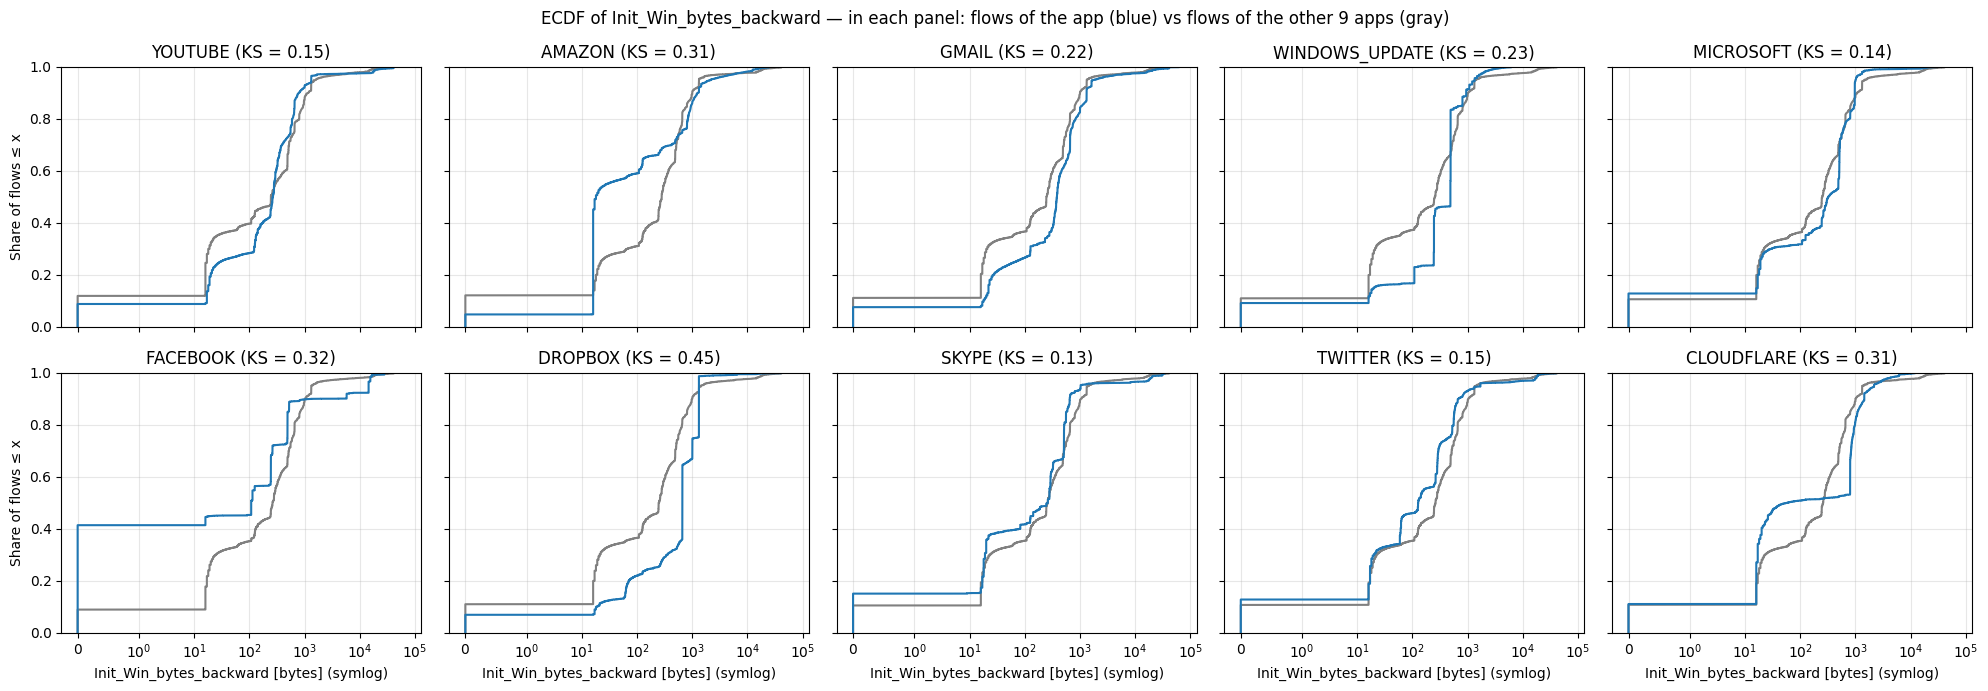

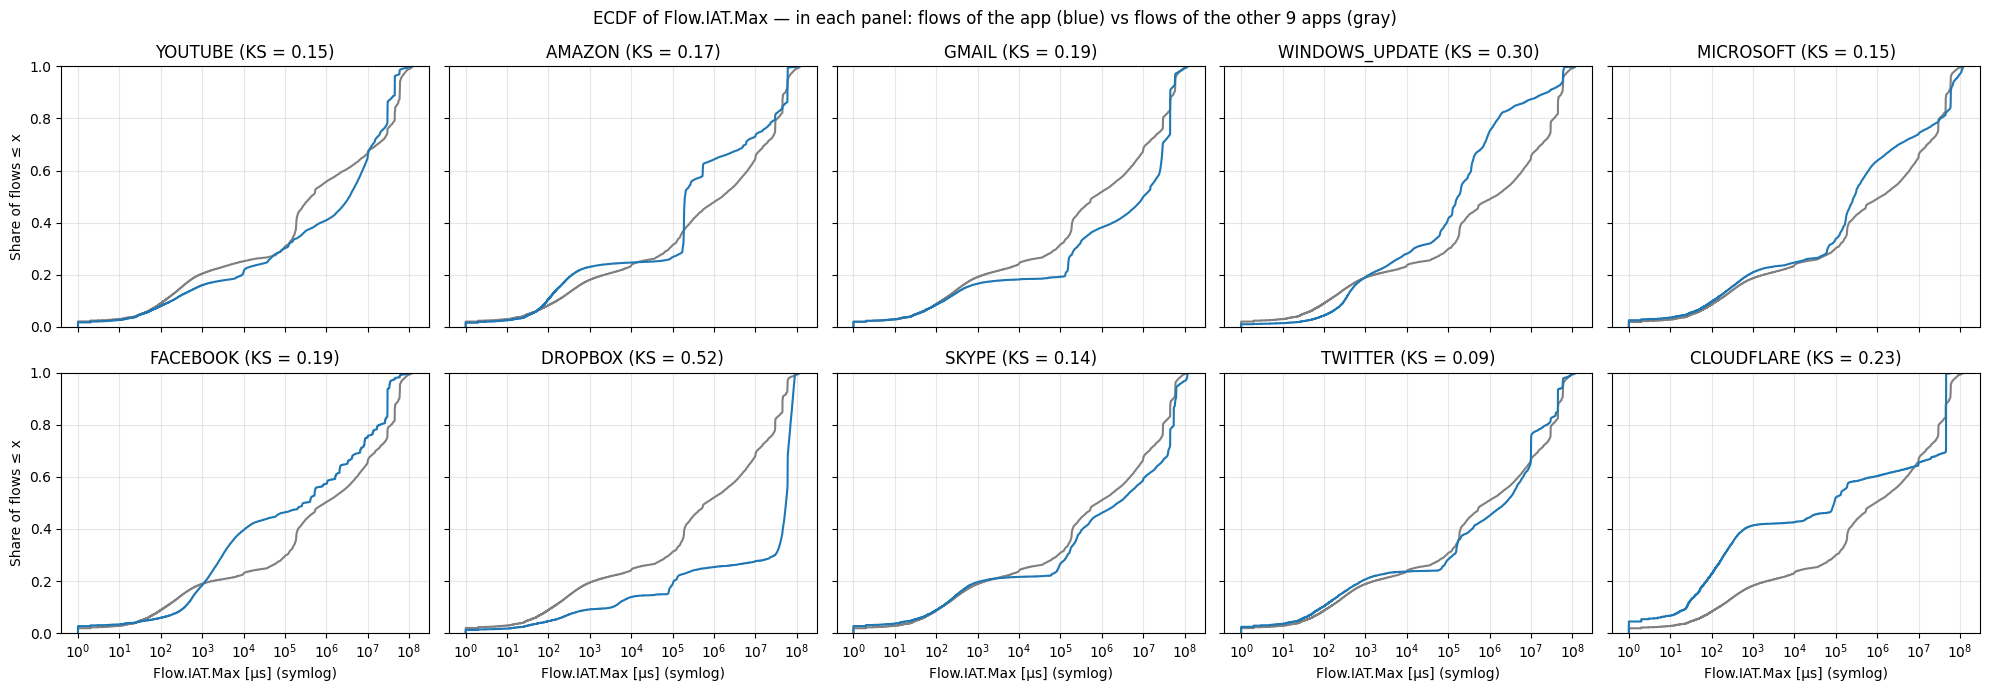

Flow.IAT.Max > 10 s [% of the flows]: {'YOUTUBE': 35.0, 'AMAZON': 27.0, 'GMAIL': 50.0, 'WINDOWS_UPDATE': 13.0, 'MICROSOFT': 26.0, 'FACEBOOK': 25.0, 'DROPBOX': 72.0, 'SKYPE': 41.0, 'TWITTER': 32.0, 'CLOUDFLARE': 35.0}
CLOUDFLARE flows with Flow.IAT.Max in [45.5, 46.5) s: 29.9%  |  AMAZON flows in [0.1, 0.2] s: 23.6%


Init_Win_bytes_backward       Flow.IAT.Max      
                                    KS   AUC           KS   AUC
YOUTUBE                           0.15  0.51         0.15  0.52
AMAZON                            0.31  0.39         0.17  0.45
GMAIL                             0.22  0.60         0.19  0.58
WINDOWS_UPDATE                    0.23  0.55         0.30  0.39
MICROSOFT                         0.14  0.53         0.15  0.46
FACEBOOK                          0.32  0.36         0.19  0.42
DROPBOX                           0.45  0.70         0.52  0.75
SKYPE                             0.13  0.46         0.14  0.55
TWITTER                           0.15  0.44         0.09  0.50
CLOUDFLARE                        0.31  0.52         0.23  0.42

In [26]:
def plot_ecdf_one_vs_rest(data, labels, feature):
    # One panel per app: ECDF of the app (blue) and of the other 9 apps (gray), with the KS statistic in the title
    fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharex=True, sharey=True)
    ks = {}
    for ax, app in zip(axes.flat, APPS):
        is_app = (labels == app).to_numpy()
        app_values, rest_values = data.loc[is_app, feature], data.loc[~is_app, feature]
        sns.ecdfplot(x=rest_values, color="gray", ax=ax)
        sns.ecdfplot(x=app_values, color="tab:blue", ax=ax)
        ks[app] = ks_2samp(app_values, rest_values).statistic
        ax.set_xscale("symlog", linthresh=1)
        ax.set_title(f"{app} (KS = {ks[app]:.2f})")
        ax.grid(True, alpha=0.3)
    for ax in axes[1]:
        ax.set_xlabel(f"{feature_label(feature)} (symlog)")
    for ax in axes[:, 0]:
        ax.set_ylabel("Share of flows ≤ x")
    fig.suptitle(f"ECDF of {feature} — in each panel: flows of the app (blue) vs flows of the other 9 apps (gray)")
    fig.tight_layout()
    return fig, pd.Series(ks)


ecdf_comparison = {}
for feature, filename in [("Init_Win_bytes_backward", "eda_ecdf_init_win_backward.png"),
                          ("Flow.IAT.Max", "eda_ecdf_flow_iat_max.png")]:
    fig, ks = plot_ecdf_one_vs_rest(X_train, y_train, feature)
    fig.savefig(PLOTS_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    ecdf_comparison[(feature, "KS")] = ks
    ecdf_comparison[(feature, "AUC")] = auc.loc[feature]

# The steps of Flow.IAT.Max discussed below
iat_s = X_train["Flow.IAT.Max"] / 1e6
print("Flow.IAT.Max > 10 s [% of the flows]:", ((iat_s > 10).groupby(y_train).mean() * 100).round(0).loc[APPS].to_dict())
print(f"CLOUDFLARE flows with Flow.IAT.Max in [45.5, 46.5) s: {iat_s[y_train == 'CLOUDFLARE'].between(45.5, 46.5, inclusive='left').mean() * 100:.1f}%  |  "
      f"AMAZON flows in [0.1, 0.2] s: {iat_s[y_train == 'AMAZON'].between(0.1, 0.2).mean() * 100:.1f}%")
pd.DataFrame(ecdf_comparison).round(2)

Observations:
- **`Init_Win_bytes_backward` is a staircase.** The curves are made of vertical steps, the specific values of the
  heatmap above: the step at 16 covers 40% of the AMAZON flows, the steps at 245 and 490 41% of WINDOWS_UPDATE, those at
  661 and 1321 51% of DROPBOX, the step at 0 41% of FACEBOOK. The gray curve is a staircase too, the mixture of the
  values of the other apps.
- **KS sees what the AUC misses.** For CLOUDFLARE the two curves are far apart (KS = 0.31) but they cross: the app has
  neither larger nor smaller values overall, so its AUC is 0.52, as if there were no separation. WINDOWS_UPDATE behaves
  the same way (KS = 0.23, AUC = 0.55). This is the non-monotonic dependence found with the mutual information, now
  visible in the plot.
- **`Flow.IAT.Max` is mostly smooth**: the apps differ by where the mass is. DROPBOX is the most separated (KS = 0.52):
  72% of its flows have a silence longer than 10 s, against 13-50% for the other apps; WINDOWS_UPDATE has shorter gaps
  than the rest (bulk downloads). But timers leave steps also on a timing feature: 30% of the CLOUDFLARE flows have a
  maximum gap of 46 s and 24% of the AMAZON flows a gap between 0.1 and 0.2 s. They look like fixed timeouts of the
  protocols or of the servers, i.e. specific values again, on a feature that an attacker can change by delaying packets.

### Scatter plots

Pairs of features are shown as one-vs-rest small multiples. To give the same visual weight to all apps, the plots use
a balanced sample of 2,000 training flows per app (with all the 400k flows the figure would be a solid blob).
Two pairs are shown: the maximum packet length in the two directions (size), and duration vs throughput (timing).

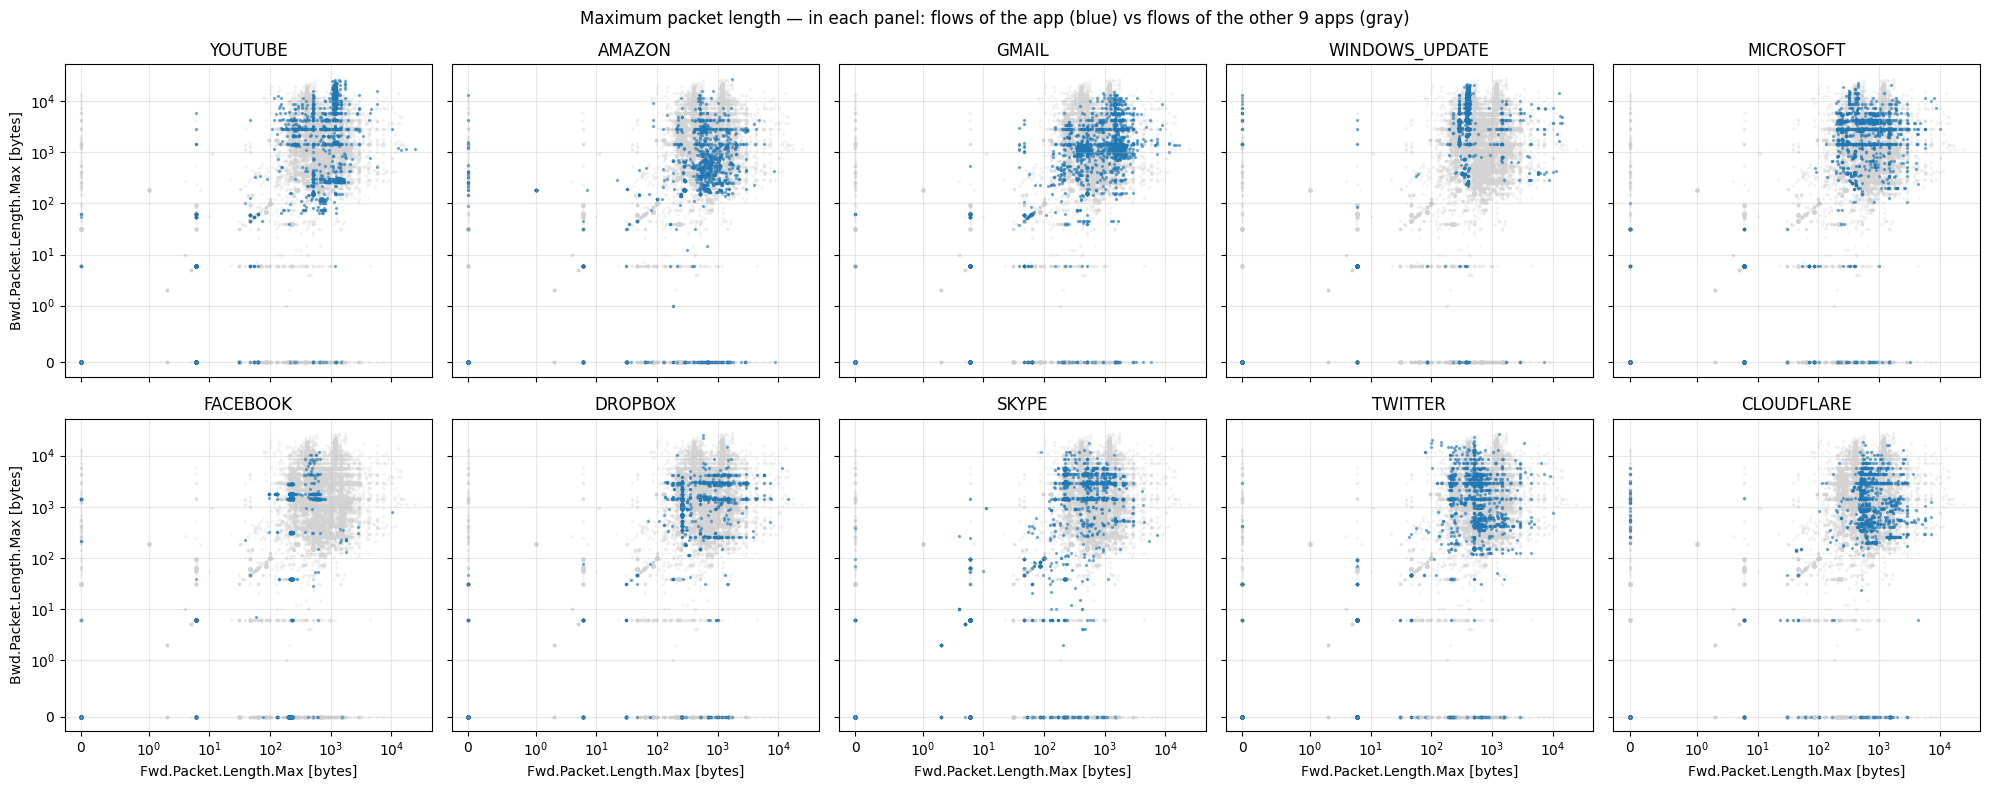

In [27]:
def plot_one_vs_rest(data, labels, x, y, title, log=True):
    # One panel per app: the flows of the app in color, those of the other 9 apps in gray
    fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True, sharey=True)
    for ax, app in zip(axes.flat, APPS):
        is_app = (labels == app).to_numpy()
        ax.scatter(data.loc[~is_app, x], data.loc[~is_app, y], s=2, alpha=0.2, color="lightgray")
        ax.scatter(data.loc[is_app, x], data.loc[is_app, y], s=2, alpha=0.5, color="tab:blue")
        if log:
            ax.set_xscale("symlog", linthresh=1)
            ax.set_yscale("symlog", linthresh=1)
        ax.set_title(app)
        ax.grid(True, alpha=0.3)
    for ax in axes[1]:
        ax.set_xlabel(feature_label(x))
    for ax in axes[:, 0]:
        ax.set_ylabel(feature_label(y))
    fig.suptitle(f"{title} — in each panel: flows of the app (blue) vs flows of the other 9 apps (gray)")
    fig.tight_layout()
    return fig


sample_X = X_train.groupby(y_train).sample(n=2000, random_state=42)
sample_y = y_train.loc[sample_X.index]

fig = plot_one_vs_rest(sample_X, sample_y, "Fwd.Packet.Length.Max", "Bwd.Packet.Length.Max", "Maximum packet length")
fig.savefig(PLOTS_DIR / "eda_scatter_packet_length.png", dpi=150, bbox_inches="tight")
plt.show()

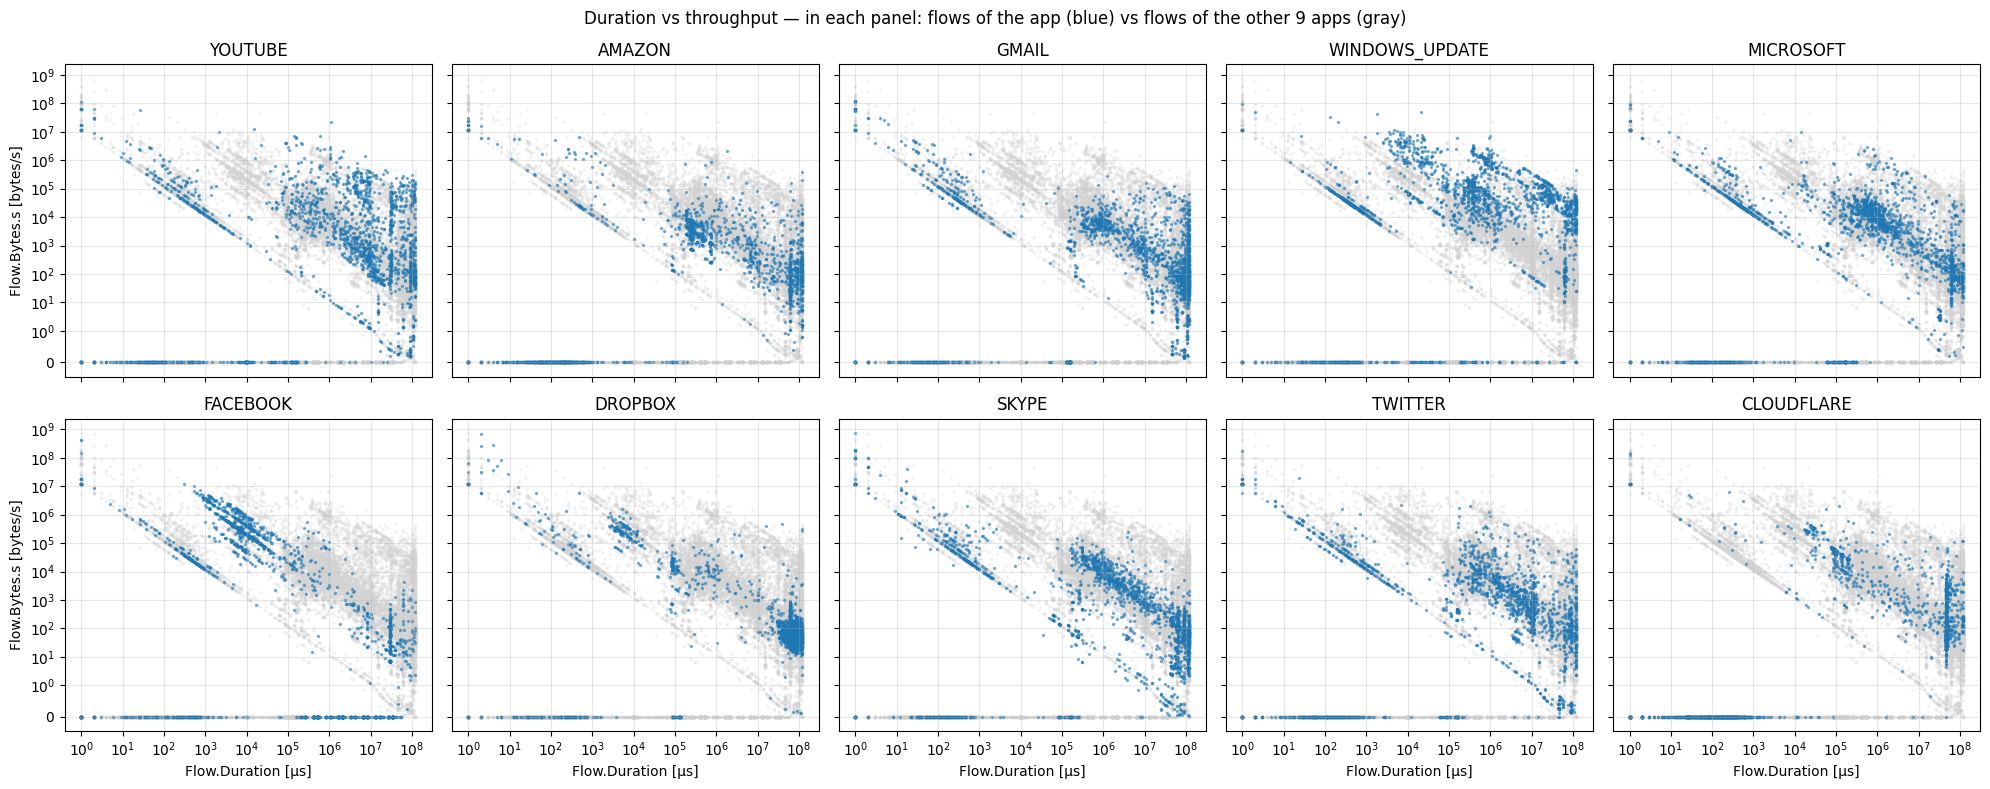

In [28]:
fig = plot_one_vs_rest(sample_X, sample_y, "Flow.Duration", "Flow.Bytes.s", "Duration vs throughput")
fig.savefig(PLOTS_DIR / "eda_scatter_duration_throughput.png", dpi=150, bbox_inches="tight")
plt.show()

Observations:
- **Maximum packet length.** The points form horizontal and vertical lines: many flows share exactly the same maximum
  size (fixed-size protocol messages). WINDOWS_UPDATE and MICROSOFT occupy the region of large backward packets,
  FACEBOOK and DROPBOX concentrate on a few specific sizes, while YOUTUBE, AMAZON and GMAIL cover almost the whole
  cloud. The flows on the axes have no payload in one direction.
- **Duration vs throughput.** Since `Flow.Bytes.s` = total bytes / duration, flows with the same number of bytes lie on
  a straight line of slope −1 in log-log scale: each diagonal is an exchange of fixed size repeated many times
  (handshakes, keep-alives, small requests). DROPBOX is concentrated on the right edge (flows of ~$10^8$ µs, close to
  the 120 s timeout, with low throughput); WINDOWS_UPDATE fills the high-throughput region; FACEBOOK sits on a few
  diagonals. The flows at `Flow.Bytes.s` = 0 carry no payload at all.
- In both plots the colored points of most apps lie inside the gray cloud: two features are not enough, but the
  apps occupy different *regions and lines*, which tree-based models and MLPs can exploit.

### PCA projection

PCA shows how much of the information is redundant and whether the apps separate along the directions of maximum
variance. As seen in the course, features must be standardized first, otherwise those with the largest numeric range
dominate the variance. `StandardScaler` is applied to `X_train_scaled` (log1p + Min-Max of Section 1.2): Min-Max is an
affine map, so this is the same as standardizing the log-transformed features, and the heavy tails do not dominate
the principal components either.

Components for 80% of the variance: 8 / 67
Components for 90% of the variance: 14 / 67
Components for 95% of the variance: 19 / 67
Components with eigenvalue > 1 (Kaiser rule): 11


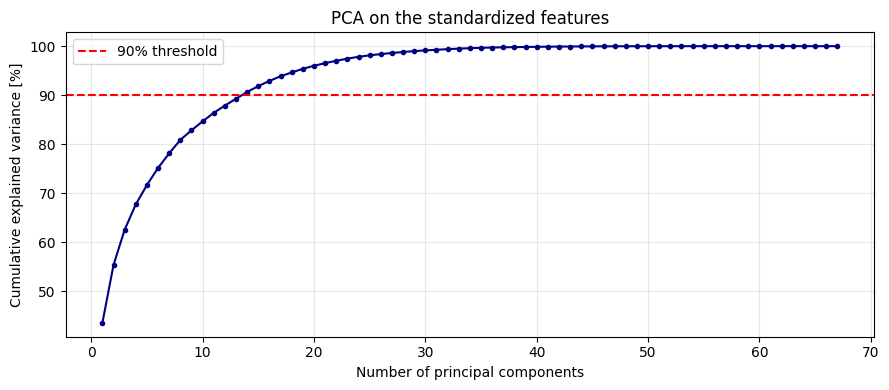

In [29]:
X_std = StandardScaler().fit_transform(X_train_scaled)
pca = PCA(random_state=15).fit(X_std)
cumul_var = np.cumsum(pca.explained_variance_ratio_) * 100

for threshold in (80, 90, 95):
    print(f"Components for {threshold}% of the variance: {np.argmax(cumul_var >= threshold) + 1} / {X_std.shape[1]}")
print(f"Components with eigenvalue > 1 (Kaiser rule): {(pca.explained_variance_ > 1).sum()}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(cumul_var) + 1), cumul_var, marker="o", markersize=3, color="navy")
ax.axhline(y=90, color="r", linestyle="--", label="90% threshold")
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance [%]")
ax.set_title("PCA on the standardized features")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_pca_variance.png", dpi=150, bbox_inches="tight")
plt.show()

In [30]:
# Variance explained by each component and cumulative, up to the components needed for 95%
n_show = np.argmax(cumul_var >= 95) + 1
pd.DataFrame({
    "eigenvalue": pca.explained_variance_[:n_show],
    "explained_variance_%": pca.explained_variance_ratio_[:n_show] * 100,
    "cumulative_variance_%": cumul_var[:n_show],
}, index=pd.RangeIndex(1, n_show + 1, name="n_components")).round(2)

,eigenvalue,explained_variance_%,cumulative_variance_%
n_components,,,
1,29.17,43.54,43.54
2,7.93,11.83,55.38
3,4.81,7.18,62.56
4,3.46,5.16,67.72
5,2.65,3.96,71.68
6,2.34,3.49,75.17
7,1.99,2.98,78.14
8,1.83,2.74,80.88
9,1.31,1.95,82.83


In [31]:
# Loading scores = components^T * sqrt(eigenvalues): correlation between each feature and each component
n_comp = 10
pca_10 = PCA(n_components=n_comp, random_state=15).fit(X_std)
loadings = pd.DataFrame(
    data=pca_10.components_.T * np.sqrt(pca_10.explained_variance_),
    columns=[f"PC{i}" for i in range(1, n_comp + 1)],
    index=X_train_scaled.columns,
)
# Top 8 features of the first 6 components, the header reports the variance explained by the component
pd.DataFrame({
    f"{pc} ({var:.1f}%)": [f"{f} ({loadings.loc[f, pc]:+.2f})" for f in loadings[pc].abs().nlargest(8).index]
    for pc, var in zip(loadings.columns[:6], pca_10.explained_variance_ratio_[:6] * 100)
})

,PC1 (43.5%),PC2 (11.8%),PC3 (7.2%),PC4 (5.2%),PC5 (4.0%),PC6 (3.5%)
0,Max.Packet.Length (+0.93),Idle.Max (+0.77),Bwd.Packets.s (+0.54),min_seg_size_forward (+0.80),Destination.Port_Other (+0.61),Init_Win_bytes_backward_missing (+0.60)
1,Packet.Length.Std (+0.93),Idle.Mean (+0.77),Down.Up.Ratio (+0.51),Destination.Port_3128 (-0.74),Bwd.Packet.Length.Min (+0.58),Init_Win_bytes_backward (-0.59)
2,Bwd.IAT.Total (+0.93),Idle.Min (+0.77),Flow.IAT.Mean (-0.50),Min.Packet.Length (-0.66),Fwd.PSH.Flags (+0.53),Down.Up.Ratio (-0.53)
3,Packet.Length.Variance (+0.93),Active.Max (+0.68),Fwd.IAT.Min (-0.50),Fwd.Packet.Length.Min (-0.60),Bwd.IAT.Min (+0.40),Destination.Port_3128 (-0.33)
4,Total.Length.of.Fwd.Packets (+0.92),Active.Mean (+0.68),Flow.Packets.s (+0.47),Destination.Port_443 (+0.52),Destination.Port_3128 (-0.38),Fwd.Header.Length (+0.30)
5,Bwd.IAT.Max (+0.92),Active.Min (+0.65),Total.Backward.Packets (+0.46),Flow.Bytes.s (-0.41),Init_Win_bytes_backward_missing (-0.34),Destination.Port_443 (+0.29)
6,Packet.Length.Mean (+0.91),Idle.Std (+0.62),Fwd.Packets.s (+0.42),Destination.Port_80 (+0.34),Init_Win_bytes_forward (-0.32),FIN.Flag.Count (+0.29)
7,Fwd.IAT.Std (+0.91),PSH.Flag.Count (-0.59),Bwd.Header.Length (+0.42),Init_Win_bytes_backward_missing (-0.32),min_seg_size_forward (+0.31),Total.Fwd.Packets (+0.27)


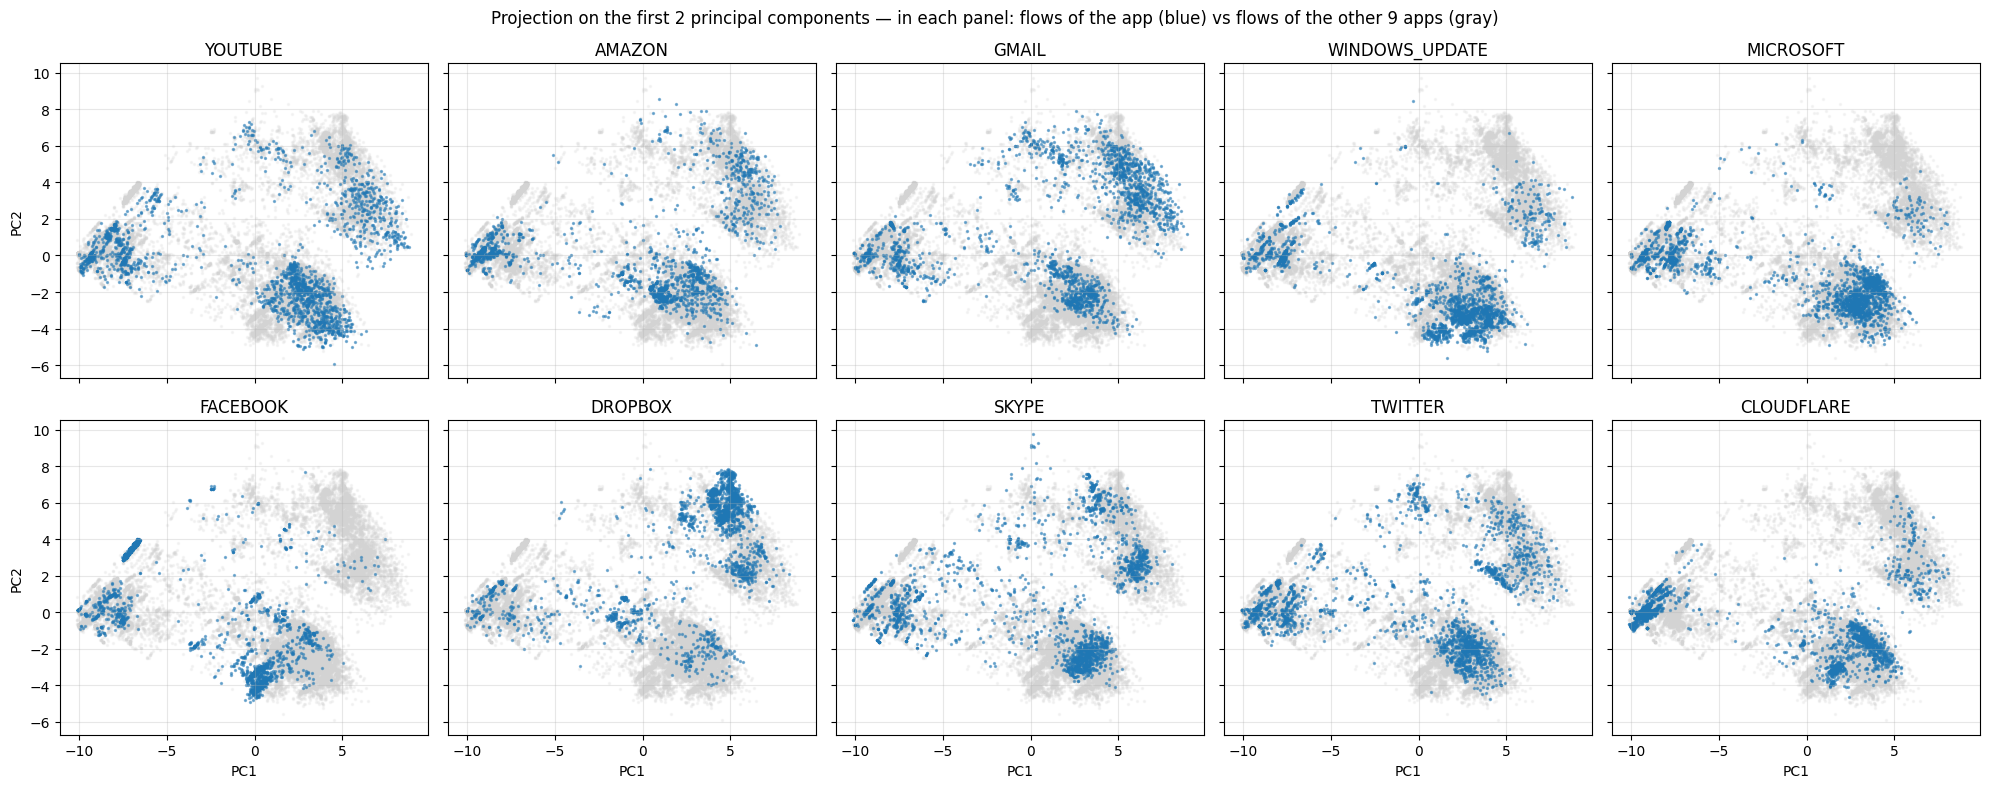

In [32]:
pcs = pd.DataFrame(pca_10.transform(X_std)[:, :2], columns=["PC1", "PC2"], index=X_train_scaled.index)
fig = plot_one_vs_rest(pcs.loc[sample_X.index], sample_y, "PC1", "PC2", "Projection on the first 2 principal components",
                       log=False)
fig.savefig(PLOTS_DIR / "eda_pca_projection.png", dpi=150, bbox_inches="tight")
plt.show()

Observations:
- **The redundancy is confirmed**: 8 components explain 80% of the variance of the 67 features, 14 explain 90%, and
  11 have an eigenvalue above 1.
- **PC1 (~43% of the variance) measures "how big" the flow is**: it loads with the same sign on packet sizes, byte and
  packet counts and durations. **PC2** (11.8%) is the active/idle behavior (`Idle.*`, `Active.*`) and **PC3** (7.2%)
  the packet rate and the balance between the two directions (`Bwd.Packets.s`, `Down.Up.Ratio`, `Flow.IAT.Mean`).
- **The app-specific features appear only from PC4 on**, in components that explain 3.5-5% of the variance each:
  PC4 opposes the proxy port 3128 to ports 443/80 together with the minimum packet and segment sizes, PC5 mixes the
  other ports with the minimum backward length and the PSH flags, PC6 opposes the missing server window to its value.
- **The projection shows three clouds**: very small flows (left, few packets without payload), ordinary flows
  (bottom right) and flows with idle periods (top right). Every app is spread over the same clouds, only in different
  proportions (DROPBOX mostly in the idle one, WINDOWS_UPDATE and MICROSOFT in the ordinary one). The directions of
  maximum variance describe the *type* of flow, not the app: the app-specific information (ports, window values,
  specific sizes) explains little variance and is lost in a 2D linear projection.
- PCA is therefore not used to reduce the inputs of the classifiers: it would not help the trees, and in Section 3 the
  perturbations must be applied to interpretable features to check whether they are realistic.

### Consequences for the models

The correlation analysis found three features that are copies of others: `Avg.Fwd.Segment.Size`,
`Avg.Bwd.Segment.Size` and `Packet.Length.Variance`. They add no information and, in Section 3, an attack that
perturbs one copy and not the other would produce flows that cannot exist, so they are removed.

The correlated features are instead kept: correlation is not identity (e.g. `Flow.Packets.s` and `Flow.IAT.Mean`
differ on the extreme values) and the redundancy does not hurt trees or the MLP.

The list is saved in `REDUNDANT_FEATURES` (`src/eda.py`), so the next notebooks drop the same columns after loading
`model_ready.csv`. `log1p` and Min-Max act on each column separately, so dropping the columns after scaling gives
the same matrix as dropping them before.

In [33]:
X_train_model = X_train_scaled.drop(columns=REDUNDANT_FEATURES)
X_test_model = X_test_scaled.drop(columns=REDUNDANT_FEATURES)
print(f"Features: {X_train_scaled.shape[1]} -> {X_train_model.shape[1]}")

Features: 67 -> 64


### Summary of the EDA

- The features are heavy-tailed, zero-inflated and strongly redundant (54 continuous features in 27 groups of
  correlated features, 90% of the variance in 14 principal components). log1p + Min-Max (Section 1.2) is a suitable
  normalization: it removes the effect of the tails without discarding the large flows, which are legitimate traffic.
  Three exact copies (the two segment sizes and the variance) are dropped, leaving 64 features; the
  correlated but not identical features are kept.
- The features that most influence the classification are:
  - the **destination port**: port 80 for AMAZON and CLOUDFLARE (partly an effect of how nDPI labels them), the inverted flows of DROPBOX, the proxy for WINDOWS_UPDATE;
  - the **initial TCP windows** `Init_Win_bytes_*`, whose specific values depend on the TCP endpoints (or the proxy) and characterize the apps;
  - the **packet sizes**, in particular the maximum and mean length in each direction;
  - the **timing** features: idle periods and maximum inter-arrival times (DROPBOX), throughput (WINDOWS_UPDATE),
    missing server answers (FACEBOOK).
- Except for CLOUDFLARE, AMAZON and DROPBOX, no single feature separates an app from the rest and the apps overlap in
  2D projections: the classifiers of Section 2 need many features and non-linear decision boundaries. Since class 1
  is always the minority (3-34%), the models must be compared with F1, recall, ROC-AUC and the area under the precision-recall curve (more sensitive
  to the false positives when the positives are only 3%) rather than accuracy. About 2.2% of the flows have the same
  features as a flow of another app, so a small error is unavoidable.
- For the attacks (Sections 3-4) the informative features differ in how much an attacker can control them: the
  destination port, the protocol and the server window cannot be changed by the client, while the size of its own
  packets (padding), the inter-arrival times (delays) and its own initial window can, but only in some directions.
  Redundant features (e.g. mean length and segment size, std and variance) should be perturbed together to keep the
  flows consistent.

## References

[1] J. S. Rojas, *IP Network Traffic Flows Labeled with 75 Apps*, Kaggle.
https://www.kaggle.com/datasets/jsrojas/ip-network-traffic-flows-labeled-with-87-apps

[2] G. Draper-Gil, A. H. Lashkari, M. S. I. Mamun, A. A. Ghorbani, "Characterization of Encrypted and VPN Traffic Using
Time-Related Features", *ICISSP*, 2016.

[3] A. H. Lashkari, G. Draper-Gil, M. S. I. Mamun, A. A. Ghorbani, "Characterization of Tor Traffic Using Time Based
Features", *ICISSP*, 2017.

[4] F. Pedregosa et al., "Scikit-learn: Machine Learning in Python", *Journal of Machine Learning Research*, 12, 2011.

[5] J. A. Hanley, B. J. McNeil, "The meaning and use of the area under a receiver operating characteristic (ROC) curve",
*Radiology*, 143(1), 1982.

[6] A. Kraskov, H. Stögbauer, P. Grassberger, "Estimating mutual information", *Physical Review E*, 69, 066138, 2004.

[7] B. C. Ross, "Mutual Information between Discrete and Continuous Data Sets", *PLoS ONE*, 9(2), e87357, 2014.

[8] D. Borman, B. Braden, V. Jacobson, R. Scheffenegger, "TCP Extensions for High Performance", RFC 7323, 2014.

[9] G. A. Miller, "Note on the bias of information estimates", in *Information Theory in Psychology: Problems and
Methods*, H. Quastler (ed.), Free Press, 1955.